# Cosmetics Store Analytics & Business Intelligence
## Section 1: Project Introduction & Business Objectives

Project Overview
This analysis looks at point-of-sale (POS) transactional data from a retail cosmetics store operating in Egypt. The dataset covers sales, purchases, product returns, inventory items, and customer account details, with all financial figures measured in Egyptian pounds (EGP).
The store’s product line includes makeup, hair care, skin care, fragrances, nail care, and accessories. The primary goal of this project is to evaluate overall business performance—specifically tracking total revenue, profitability, customer purchasing behavior, top-performing products, and operational flags like stock discrepancies or high return rates.

### Business problem
The store saves a lot of data every day, but the raw tables do not tell us the story. The problem in this project is to turn these tables into clear numbers about sales, profit, customers, products, inventory, and returns.


Import Libraries
Here we import standard libraries for data analysis and plotting. We use pandas for data manipulation, numpy for calculations, and matplotlib for charts.

In [1]:
from pathlib import Path  #--> Path --> للتعامل مع مسارات الملفات والمجلدات بطريقة مرنة
import filecmp  #--> cmp() --> للمقارنة بين الملفات والتأكد من تطابقها
import pandas as pd 
import numpy as np  
import matplotlib.pyplot as plt  #--> plt --> لرسم وتنسيق المخططات البيانية Visualizations
import seaborn as sns
import plotly.express as px

plt.style.use('seaborn-v0_8-whitegrid')  #--> use() --> بيحدد النمط والشكل  للمخططات البيانية
plt.rcParams['font.size'] = 10  #--> بيحدد حجم الخط الأساسي لكل النصوص داخل الرسومات
plt.rcParams['figure.titlesize'] = 12  #--> بيحدد حجم خط العناوين الرئيسية للرسومات البيانية

Load Standardized Datasets

In [2]:
current_dir = Path.cwd()  #--> cwd() --> بيرجع مسار مجلد العمل الحالي
if current_dir.name == "notebooks":  #--> بيتحقق لو المسار الحالي داخل مجلد notebooks
    project_root = current_dir.parent  #--> parent --> بيرجع للمجلد الرئيسي للمشروع
else:  #--> في حالة لو كنا بالفعل في المجلد الرئيسي
    project_root = current_dir  #--> بيعتمد المجلد الحالي كمسار رئيسي

data_dir = project_root / "data" / "processed"  #--> بيحدد مسار مجلد البيانات النظيفة الجاهزة للتحليل

print("Project Root:", project_root)  #--> print() --> بيطبع المسار الرئيسي   
print("Data Directory:", data_dir)  #--> print() --> بيطبع مسار مجلد البيانات  

Project Root: c:\Depi\FinalProject\cosmetics_store_rebuild
Data Directory: c:\Depi\FinalProject\cosmetics_store_rebuild\data\processed


In [3]:
accounts_df = pd.read_csv(data_dir / "cleaned_accounts.csv")  #--> read_csv() --> بيقرأ ملف الحسابات ويحفظه في DataFrame
products_df = pd.read_csv(data_dir / "cleaned_products.csv", dtype={'barcode': str})  #--> read_csv() --> بيقرأ ملف المنتجات مع تحديد نوع الباركود كنص String
sales_invoices_df = pd.read_csv(data_dir / "cleaned_sales_invoices.csv") 
sales_items_df = pd.read_csv(data_dir / "cleaned_sales_items.csv") 
purchase_invoices_df = pd.read_csv(data_dir / "cleaned_purchase_invoices.csv")  
purchase_items_df = pd.read_csv(data_dir / "cleaned_purchase_items.csv")  
returns_invoices_df = pd.read_csv(data_dir / "cleaned_sales_returns_invoices.csv")  
returns_items_df = pd.read_csv(data_dir / "cleaned_sales_returns_items.csv")  

print(f"Accounts Master:{len(accounts_df):,d} rows")  #--> len() --> بيرجع عدد صفوف جدول الحسابات 
print(f"Products Catalog:{len(products_df):,d} rows")  #--> len() --> بيرجع عدد صفوف جدول المنتجات 
print(f"Sales Invoices:{len(sales_invoices_df):,d} rows")  #--> len() --> بيرجع عدد صفوف جدول فواتير المبيعات 
print(f"Sales Line Items:{len(sales_items_df):,d} rows")  #--> len() --> بيرجع عدد صفوف جدول بنود المبيعات 
print(f"Purchase Invoices:{len(purchase_invoices_df):,d} rows")  #--> len() --> بيرجع عدد صفوف جدول المشتريات 
print(f"Purchase Line Items:{len(purchase_items_df):,d} rows")  #--> len() --> بيرجع عدد صفوف جدول بنود المشتريات 
print(f"Sales Return Invoices:{len(returns_invoices_df):,d} rows")  #--> len() --> بيرجع عدد صفوف جدول فواتير المرتجعات 
print(f"Sales Return Line Items: {len(returns_items_df):,d} rows")  #--> len() --> بيرجع عدد صفوف جدول بنود المرتجعات 

Accounts Master:37 rows
Products Catalog:1,437 rows
Sales Invoices:5,505 rows
Sales Line Items:10,891 rows
Purchase Invoices:32 rows
Purchase Line Items:1,658 rows
Sales Return Invoices:127 rows
Sales Return Line Items: 157 rows


### Initial Data Inspection & Dimensions


In [4]:
datasets_summary = pd.DataFrame([  #--> DataFrame() --> بينشئ جدول ملخص لجميع الملفات المحملة
    {"Dataset Name": "Accounts Master", "Table Variable": "accounts_df", "Rows": len(accounts_df), "Columns": accounts_df.shape[1], "Primary Key / ID": "acct_no"},  #--> len() --> عدد الصفوف , shape --> عدد الأعمدة
    {"Dataset Name": "Products Catalog", "Table Variable": "products_df", "Rows": len(products_df), "Columns": products_df.shape[1], "Primary Key / ID": "item_code"}, 
    {"Dataset Name": "Sales Invoices", "Table Variable": "sales_invoices_df", "Rows": len(sales_invoices_df), "Columns": sales_invoices_df.shape[1], "Primary Key / ID": "invoice_no"}, 
    {"Dataset Name": "Sales Items", "Table Variable": "sales_items_df", "Rows": len(sales_items_df), "Columns": sales_items_df.shape[1], "Primary Key / ID": "invoice_no, item_code"},  
    {"Dataset Name": "Purchase Invoices", "Table Variable": "purchase_invoices_df", "Rows": len(purchase_invoices_df), "Columns": purchase_invoices_df.shape[1], "Primary Key / ID": "invoice_no"}, 
    {"Dataset Name": "Purchase Items", "Table Variable": "purchase_items_df", "Rows": len(purchase_items_df), "Columns": purchase_items_df.shape[1], "Primary Key / ID": "invoice_no, item_code"},  
    {"Dataset Name": "Returns Invoices", "Table Variable": "returns_invoices_df", "Rows": len(returns_invoices_df), "Columns": returns_invoices_df.shape[1], "Primary Key / ID": "return_invoice_no"},  
    {"Dataset Name": "Returns Items", "Table Variable": "returns_items_df", "Rows": len(returns_items_df), "Columns": returns_items_df.shape[1], "Primary Key / ID": "return_invoice_no, item_code"}  #--> len() --> عدد الصفوف , shape --> عدد الأعمدة
])  

datasets_summary  #--> عرض جدول الملخص مباشرة في الخلية

,Dataset Name,Table Variable,Rows,Columns,Primary Key / ID
0,Accounts Master,accounts_df,37,19,acct_no
1,Products Catalog,products_df,1437,15,item_code
2,Sales Invoices,sales_invoices_df,5505,33,invoice_no
3,Sales Items,sales_items_df,10891,12,"invoice_no, item_code"
4,Purchase Invoices,purchase_invoices_df,32,22,invoice_no
5,Purchase Items,purchase_items_df,1658,10,"invoice_no, item_code"
6,Returns Invoices,returns_invoices_df,127,29,return_invoice_no
7,Returns Items,returns_items_df,157,11,"return_invoice_no, item_code"


In [5]:
tables = [  #--> قائمة تجمع أسماء الجداول ومتغيراتها
    ('accounts_df', accounts_df),  #--> جدول الحسابات
    ('products_df', products_df),  #--> جدول المنتجات
    ('sales_invoices_df', sales_invoices_df),  #--> جدول فواتير المبيعات
    ('sales_items_df', sales_items_df),  #--> جدول بنود فواتير المبيعات
    ('purchase_invoices_df', purchase_invoices_df),  #--> جدول فواتير المشتريات
    ('purchase_items_df', purchase_items_df),  #--> جدول بنود المشتريات
    ('returns_invoices_df', returns_invoices_df),  #--> جدول فواتير المرتجعات
    ('returns_items_df', returns_items_df)  #--> جدول بنود المرتجعات
]  
all_dfs = dict(tables)  #--> dict() --> بيحول القائمة إلى قاموس للوصول السريع للجداول

for name, df in tables:  #--> للمرور على كل جدول وعرض نوع بيانات أعمدته
    print(f"Table: {name} ({df.shape[1]} columns)")  #--> print() --> بيطبع اسم الجدول وعدد أعمدته
    info_df = pd.DataFrame({'Column': df.columns, 'Type': df.dtypes.astype(str)})  #--> DataFrame() --> بينشئ جدول لأنواع البيانات , astype(str) --> بيحول الأنواع لنصوص
    display(info_df)  #--> display() --> بيعرض جدول أنواع البيانات بشكل منسق

Table: accounts_df (19 columns)


,Column,Type
idx,idx,int64
acct_no,acct_no,int64
acct_name,acct_name,str
balance_debit,balance_debit,float64
balance_credit,balance_credit,float64
checks_debit,checks_debit,int64
checks_credit,checks_credit,int64
nature,nature,str
category,category,str
acct_code,acct_code,float64


Table: products_df (15 columns)


,Column,Type
idx,idx,int64
item_code,item_code,int64
item_name,item_name,str
total_qty,total_qty,float64
unit,unit,float64
sell_price,sell_price,float64
avg_purchase_price,avg_purchase_price,float64
last_purchase_price,last_purchase_price,float64
barcode,barcode,str
item_code_1_MISLABELED,item_code_1_MISLABELED,float64


Table: sales_invoices_df (33 columns)


,Column,Type
counter,counter,int64
date,date,str
time,time,str
invoice_no,invoice_no,int64
acct_no,acct_no,float64
account,account,str
customer_type,customer_type,str
internal_account_status,internal_account_status,str
is_internal_account,is_internal_account,bool
is_retail_sale,is_retail_sale,bool


... (6 outputs left out)

Table: returns_invoices_df (29 columns)


,Column,Type
row_index,row_index,int64
counter,counter,int64
date,date,str
time,time,str
return_invoice_no,return_invoice_no,int64
original_invoice_no,original_invoice_no,int64
account,account,str
payment_method,payment_method,str
total_qty,total_qty,int64
total_discount,total_discount,int64


Table: returns_items_df (11 columns)


,Column,Type
invoice_row_index,invoice_row_index,int64
return_invoice_no,return_invoice_no,int64
item_code,item_code,int64
item_name,item_name,str
unit,unit,float64
available_qty,available_qty,int64
qty,qty,int64
price,price,float64
discount,discount,float64
profit,profit,float64


In [6]:
print(" Sales Invoices Sample (First 3 Rows) ")  #--> print() --> بيطبع عينة فواتير المبيعات
display(sales_invoices_df[['invoice_no', 'invoice_date', 'customer_type', 'payment_method', 'total_qty', 'final_total', 'profit']].head(3))  #--> head(3) --> بيرجع أول 3 صفوف , display() --> بيعرض العينة المحددة

print("\n Products Catalog Sample (First 3 Rows)")  #--> print() --> بيطبع عينة كتالوج المنتجات
display(products_df[['item_code', 'item_name', 'product_scope', 'product_category', 'total_qty', 'sell_price', 'avg_purchase_price', 'stock_cost_valuation']].head(3))  #--> head(3) --> بيرجع أول 3 صفوف , display() --> بيعرض العينة المحددة

 Sales Invoices Sample (First 3 Rows) 


,invoice_no,invoice_date,customer_type,payment_method,total_qty,final_total,profit
0,5531,2026-09-14,Walk-in Retail,نقدي,1.0,90.0,20.0100
1,5530,2026-09-14,Walk-in Retail,نقدي,1.0,95.0,18.3500
2,5529,2026-09-14,Walk-in Retail,نقدي,1.0,200.0,36.1111



 Products Catalog Sample (First 3 Rows)


,item_code,item_name,product_scope,product_category,total_qty,sell_price,avg_purchase_price,stock_cost_valuation
0,4,اكلادور كوكو اوريجنال,In-Scope (Beauty),Nail Care,7.0,35.0,28.5,199.5
1,5,شراب سيليكون,In-Scope (Beauty),Uncategorized,0.0,55.0,44.0,0.0
2,6,قصافه 2*1 علي كارت,In-Scope (Beauty),Accessories & Tools,-7.0,35.0,19.5,-136.5


In [7]:
sales_invoices_df[['total_qty', 'total_discount', 'final_total', 'profit']].describe().round(2)  #--> describe() --> بيحسب الإحصاءات الوصفية , round(2) --> بيقرب الأرقام لخانة عشرية ثنائية

,total_qty,total_discount,final_total,profit
count,5505.00,5505.00,5505.00,5505.00
mean,2.27,4.14,177.70,36.07
std,4.91,24.57,780.02,116.15
min,0.25,0.00,0.00,-540.00
25%,1.00,0.00,50.00,11.01
50%,1.00,0.00,100.00,20.21
75%,2.00,0.00,180.00,38.86
max,237.50,785.00,47207.00,5845.35


## Data Cleaning Explanation & Audit
Here we audit the cleaned tables. We check primary key uniqueness, inspect missing values in each table, and verify unit costs and date ranges.

In [8]:
sales_dup = sales_invoices_df['invoice_no'].duplicated().sum()  #--> duplicated() --> بيحدد الصفوف المكررة , sum() --> بيجمع عدد التكرارات
products_dup = products_df['item_code'].duplicated().sum()  
accounts_dup = accounts_df['acct_no'].duplicated().sum()  
purch_dup = purchase_invoices_df['invoice_no'].duplicated().sum()  
ret_dup = returns_invoices_df['return_invoice_no'].duplicated().sum()  
print("Primary Key Uniqueness / Duplicate Check:")  #--> print() --> بيطبع عنوان فحص تكرار المفاتيح الأساسية
check_list = [                             #--> قائمة تضم الأعمدة وعدد التكرارات المفحوصة
    ("sales_invoices_df['invoice_no']", sales_dup),  #--> فحص تكرار فواتير المبيعات
    ("products_df['item_code']", products_dup),  #--> فحص تكرار أكواد المنتجات
    ("accounts_df['acct_no']", accounts_dup),  #--> فحص تكرار أرقام الحسابات
    ("purchase_invoices_df['invoice_no']", purch_dup),  #--> فحص تكرار فواتير المشتريات
    ("returns_invoices_df['return_invoice_no']", ret_dup)  #--> فحص تكرار فواتير المرتجعات
] 

for col_name, dup_count in check_list:  #-->  طباعة نتائج فحص التكرارات
    if dup_count == 0:  #--> شرط للتأكد من عدم وجود أي تكرار
        status_msg = "PASS (Unique)"  #--> رسالة النجاح في حالة عدم وجود تكرار
    else:  #--> في حالة وجود تكرار
        status_msg = f"FAIL ({dup_count} duplicates found)"  #--> رسالة تحذير بعدد التكرارات الموجودة
    print(f"  {col_name:<40}: {dup_count} ({status_msg})")  #--> print() --> بيطبع اسم المفتاح والنتيجة  

Primary Key Uniqueness / Duplicate Check:
  sales_invoices_df['invoice_no']         : 0 (PASS (Unique))
  products_df['item_code']                : 0 (PASS (Unique))
  accounts_df['acct_no']                  : 0 (PASS (Unique))
  purchase_invoices_df['invoice_no']      : 0 (PASS (Unique))
  returns_invoices_df['return_invoice_no']: 0 (PASS (Unique))


In [9]:
for name, df in tables:  #--> لفحص القيم المفقودة في كل الجداول
    missing_series = df.isnull().sum()  #--> isnull() --> بيكتشف القيم الفارغة , sum() --> بيجمع عدد القيم المفقودة لكل عمود
    cols_with_missing = missing_series[missing_series > 0]  #--> تصفية الأعمدة التي تحتوي فقط على قيم مفقودة
    print(f"\n {name} Missing Values ({len(cols_with_missing)} columns with nulls out of {df.shape[1]}) ")  #--> len() --> عدد الأعمدة ذات القيم الفارغة , print() --> بيطبع ملخص الجدول
    if len(cols_with_missing) > 0:  #--> شرط في حالة وجود أعمدة بها قيم فارغة
        missing_df = pd.DataFrame({  #--> DataFrame() --> بينشئ جدول لتفاصيل القيم المفقودة
            "Missing Count": cols_with_missing,  #--> عدد القيم الفارغة في العمود
            "Missing Pct %": (cols_with_missing / len(df) * 100).round(2)  #--> round(2) --> بيحسب النسبة المئوية للغياب ويقربها لخانة عشرية
        })  
        display(missing_df)  #--> display() --> بيعرض جدول القيم المفقودة
    else: 
        print("Zero missing values across all columns")  #--> print() --> بيطبع تأكيد عدم وجود أي قيم مفقودة


 accounts_df Missing Values (7 columns with nulls out of 19) 


,Missing Count,Missing Pct %
category,36,97.30
acct_code,37,100.00
mobile,37,100.00
address,37,100.00
review_date,37,100.00
last_sale_date,17,45.95
last_receipt_date,26,70.27



 products_df Missing Values (3 columns with nulls out of 15) 


,Missing Count,Missing Pct %
unit,1437,100.00
barcode,34,2.37
source_category,1435,99.86



 sales_invoices_df Missing Values (5 columns with nulls out of 33) 


,Missing Count,Missing Pct %
acct_no,5417,98.40
account,5417,98.40
sales_rep,5505,100.00
modified_by,5301,96.29
modified_time,5301,96.29


... (6 outputs left out)


 returns_invoices_df Missing Values (4 columns with nulls out of 29) 


,Missing Count,Missing Pct %
account,122,96.06
sales_rep,127,100.00
modified_by,126,99.21
modified_time,126,99.21



 returns_items_df Missing Values (1 columns with nulls out of 11) 


,Missing Count,Missing Pct %
unit,157,100.0


In [10]:
print(" Unit Cost Verification in Sales Item")  
cost_diff = (sales_items_df['line_final'] - sales_items_df['profit']) - (sales_items_df['unit_cost'] * sales_items_df['qty'])  #--> بيحسب الفرق الحسابي بين التكلفة الإجمالية وتكلفة القطع
print(f"Max unit cost difference: {cost_diff.abs().max():.4f} EGP")  #--> abs() --> بيرجع القيمة المطلقة , max() --> بيحدد أكبر فرق حسابي , print() --> بيطبع أقصى فرق

print("\n Calendar Date Boundaries")  #--> print() --> بيطبع عنوان النطاق الزمني للبيانات
print(f"Sales Invoices:{sales_invoices_df['invoice_date'].min()} to {sales_invoices_df['invoice_date'].max()} ({sales_invoices_df['invoice_date'].nunique()} unique sale days)")  #--> min() --> أقدم تاريخ , max() --> أحدث تاريخ , nunique() --> عدد الأيام الفريدة
print(f"Sales Returns:{returns_invoices_df['return_date'].min()} to {returns_invoices_df['return_date'].max()} ({returns_invoices_df['return_date'].nunique()} unique return days)")  #--> min() --> أقدم تاريخ , max() --> أحدث تاريخ , nunique() --> عدد الأيام الفريدة
print(f"Purchase Orders:{purchase_invoices_df['purchase_date'].min()} to {purchase_invoices_df['purchase_date'].max()} ({purchase_invoices_df['purchase_date'].nunique()} unique purchase days)")  #--> min() --> أقدم تاريخ , max() --> أحدث تاريخ , nunique() --> عدد الأيام الفريدة

 Unit Cost Verification in Sales Item
Max unit cost difference: 0.0000 EGP

 Calendar Date Boundaries
Sales Invoices:2025-11-28 to 2026-09-14 (289 unique sale days)
Sales Returns:2025-11-28 to 2026-09-23 (94 unique return days)
Purchase Orders:2025-11-23 to 2026-08-01 (21 unique purchase days)


## Customer Segmentation Analysis


In [11]:
segment_summary = sales_invoices_df.groupby('customer_type').agg(  #--> groupby() --> بيجمع البيانات حسب نوع العميل , agg() --> بيطبق دوال التجميع الحسابية
    invoices=('invoice_no', 'count'),  #--> count() --> بيحسب إجمالي عدد الفواتير
    revenue=('final_total', 'sum'),  #--> sum() --> بيحسب إجمالي الإيرادات
    profit=('profit', 'sum')  #--> sum() --> بيحسب إجمالي الأرباح
).reset_index()  #--> reset_index() --> بيعيد تعيين الفهرس لعمود 

total_revenue = sales_invoices_df['final_total'].sum()  #--> sum() --> بيحسب المجموع الكلي للإيرادات
total_profit = sales_invoices_df['profit'].sum()  #--> sum() --> بيحسب المجموع الكلي للأرباح
total_invoices = len(sales_invoices_df)  #--> len() --> بيحسب إجمالي عدد الفواتير الكلي

segment_summary['invoices_share_pct'] = (segment_summary['invoices'] / total_invoices * 100).round(2)  #--> round(2) --> بيحسب النسبة المئوية لعدد الفواتير ويقربها
segment_summary['revenue_share_pct'] = (segment_summary['revenue'] / total_revenue * 100).round(2)  #--> round(2) --> بيحسب النسبة المئوية لحصة الإيراد ويقربها
segment_summary['profit_margin_pct'] = (segment_summary['profit'] / segment_summary['revenue'] * 100).round(2)  #--> round(2) --> بيحسب هامش الربح المئوي ويقربه
segment_summary['aov_egp'] = (segment_summary['revenue'] / segment_summary['invoices']).round(2)  #--> round(2) --> بيحسب متوسط قيمة الفاتورة AOV ويقربه

segment_summary['revenue'] = segment_summary['revenue'].round(2)  #--> round(2) --> بيقرب عمود الإيرادات لخانة عشرية
segment_summary['profit'] = segment_summary['profit'].round(2)  #--> round(2) --> بيقرب عمود الأرباح لخانة عشرية
segment_summary['aov_egp'] = segment_summary['aov_egp'].round(2)  #--> round(2) --> بيقرب متوسط قيمة الفاتورة لخانة عشرية

display(segment_summary)  #--> display() --> بيعرض جدول ملخص شرائح العملاء

,customer_type,invoices,revenue,profit,invoices_share_pct,revenue_share_pct,profit_margin_pct,aov_egp
0,Internal Partner,26,54684.50,3380.14,0.47,5.59,6.18,2103.25
1,Registered Commercial,57,53161.65,13190.92,1.04,5.43,24.81,932.66
2,Supplier Settlement,5,10870.00,-231.83,0.09,1.11,-2.13,2174.00
3,Walk-in Retail,5417,859532.14,182251.17,98.40,87.86,21.20,158.67


In [12]:
print("Customer Segmentation Validation Benchmark:")  
for _, row in segment_summary.iterrows():  #--> iterrows() --> بيمر على صفوف الجدول صفاً صفاً
    print(f"{row['customer_type']:<22}: {row['invoices']:>5,d} invoices | {row['revenue']:>10,.2f} EGP revenue | {row['profit']:>9,.2f} EGP profit")  #--> print() --> بيطبع تفاصيل كل شريحة بتنسيق آلاف

print(f" {'TOTAL':<22}: {segment_summary['invoices'].sum():>5,d} invoices | {segment_summary['revenue'].sum():>10,.2f} EGP revenue | {segment_summary['profit'].sum():>9,.2f} EGP profit")  #--> sum() --> بيجمع الإجماليات , print() --> بيطبع السطر الإجمالي

Customer Segmentation Validation Benchmark:
Internal Partner      :    26 invoices |  54,684.50 EGP revenue |  3,380.14 EGP profit
Registered Commercial :    57 invoices |  53,161.65 EGP revenue | 13,190.92 EGP profit
Supplier Settlement   :     5 invoices |  10,870.00 EGP revenue |   -231.83 EGP profit
Walk-in Retail        : 5,417 invoices | 859,532.14 EGP revenue | 182,251.17 EGP profit
 TOTAL                 : 5,505 invoices | 978,248.29 EGP revenue | 198,590.40 EGP profit


In [13]:
external_demand = sales_invoices_df[sales_invoices_df['customer_type'].isin(['Walk-in Retail', 'Registered Commercial'])]  #--> isin() --> بيصفي فواتير العملاء الخارجيين قطاعي وتجاري
partner_txns = sales_invoices_df[sales_invoices_df['customer_type'] == 'Internal Partner']  #--> بيصفي معاملات الشريك الداخلي فقط
supplier_txns = sales_invoices_df[sales_invoices_df['customer_type'] == 'Supplier Settlement']  #--> بيصفي تسويات الموردين فقط

sensitivity_df = pd.DataFrame([  #--> DataFrame() --> بينشئ جدول تحليل الحساسية لتقسيم المعاملات
    {
        "Transaction Group": "External Customer Transactions (Walk-in + Registered Commercial)",
        "Invoices": len(external_demand),  #--> len() --> بيحسب عدد فواتير العملاء الخارجيين
        "Revenue (EGP)": external_demand['final_total'].sum(),  #--> sum() --> بيجمع إيرادات العملاء الخارجيين
        "Revenue Share %": round(external_demand['final_total'].sum() / total_revenue * 100, 2),  #--> round() --> بيحسب النسبة المئوية لحصة إيراد العملاء الخارجيين
        "Gross Profit (EGP)": external_demand['profit'].sum(),  #--> sum() --> بيجمع أرباح العملاء الخارجيين
        "Profit Margin %": round(external_demand['profit'].sum() / external_demand['final_total'].sum() * 100, 2)  #--> round() --> بيحسب هامش الربح للعملاء الخارجيين
    },
    {
        "Transaction Group": "Internal Partner Transactions",
        "Invoices": len(partner_txns),  #--> len() --> بيحسب عدد فواتير معاملات الشريك
        "Revenue (EGP)": partner_txns['final_total'].sum(),  #--> sum() --> بيجمع إيرادات الشريك
        "Revenue Share %": round(partner_txns['final_total'].sum() / total_revenue * 100, 2),  #--> round() --> بيحسب نسبة إيرادات الشريك
        "Gross Profit (EGP)": partner_txns['profit'].sum(),  #--> sum() --> بيجمع أرباح الشريك
        "Profit Margin %": round(partner_txns['profit'].sum() / partner_txns['final_total'].sum() * 100, 2)  #--> round() --> بيحسب هامش ربح الشريك
    },
    {
        "Transaction Group": "Supplier Settlement",
        "Invoices": len(supplier_txns),  #--> len() --> بيحسب عدد فواتير تسويات الموردين
        "Revenue (EGP)": supplier_txns['final_total'].sum(),  #--> sum() --> بيجمع إيرادات التسويات
        "Revenue Share %": round(supplier_txns['final_total'].sum() / total_revenue * 100, 2),  #--> round() --> بيحسب نسبة إيرادات التسويات
        "Gross Profit (EGP)": supplier_txns['profit'].sum(),  #--> sum() --> بيجمع أرباح التسويات
        "Profit Margin %": round(supplier_txns['profit'].sum() / supplier_txns['final_total'].sum() * 100, 2)  #--> round() --> بيحسب هامش ربح التسويات
    }
]) 

sensitivity_df  #--> عرض جدول تحليل الحساسية

,Transaction Group,Invoices,Revenue (EGP),Revenue Share %,Gross Profit (EGP),Profit Margin %
0,External Customer Transactions (Walk-in + Regi...,5474,912693.79,93.30,195442.0919,21.41
1,Internal Partner Transactions,26,54684.50,5.59,3380.1442,6.18
2,Supplier Settlement,5,10870.00,1.11,-231.8300,-2.13


##  Product Categorization & Scope Governance


In [14]:
scope_summary = products_df['product_scope'].value_counts().reset_index()  #--> value_counts() --> بيحسب تكرار كل نطاق للمنتجات , reset_index() --> بيعيد تعيين الفهرس لجدول
scope_summary.columns = ['Product Scope', 'SKU Count']  #--> بيحدد أسماء الأعمدة في الجدول
scope_summary['Share %'] = (scope_summary['SKU Count'] / len(products_df) * 100).round(2)  #--> len() --> إجمالي عدد المنتجات , round(2) --> بيحسب نسبة كل نطاق ويقربها

print(f"Total Products in Catalog: {len(products_df):,d} SKUs")  #--> len() --> بيحسب إجمالي المنتجات , print() --> بيطبع الإجمالي بتنسيق آلاف
scope_summary  #--> عرض جدول ملخص نطاقات المنتجات

Total Products in Catalog: 1,437 SKUs


,Product Scope,SKU Count,Share %
0,In-Scope (Beauty),1185,82.46
1,Pending Review,206,14.34
2,Out-of-Scope (Personal Care),40,2.78
3,Out-of-Scope (Packaging),4,0.28
4,In-Scope (Fashion),2,0.14


In [15]:
full_category_summary = products_df['product_category'].value_counts().reset_index()  #--> value_counts() --> بيحسب تكرار كل قسم في المنتجات , reset_index() --> بيحول الناتج لجدول
full_category_summary.columns = ['Department Category', 'SKU Count']  #--> بيحدد أسماء أعمدة جدول الأقسام
full_category_summary['Catalog Share %'] = (full_category_summary['SKU Count'] / len(products_df) * 100).round(2)  #--> len() --> إجمالي المنتجات , round(2) --> بيحسب نسبة كل قسم

print("Full-Catalog Department Counts (including Uncategorized):")  #--> print() --> بيطبع عنوان جدول الأقسام الكلي
display(full_category_summary)  #--> display() --> بيعرض جدول إحصاءات الأقسام

print("\nCross-Tabulation: product_scope vs. product_category:")  #--> print() --> بيطبع عنوان جدول التقاطع بين النطاق والقسم
crosstab_scope_cat = pd.crosstab(products_df['product_scope'], products_df['product_category'], margins=True)  #--> crosstab() --> بيحسب التوزيع التكراري المتقاطع بين عمودين مع الإجماليات
display(crosstab_scope_cat)  #--> display() --> بيعرض جدول التوزيع المتقاطع

uncat_df = products_df[products_df['product_category'] == 'Uncategorized']  #--> بيصفي المنتجات غير المصنفة في الأقسام
total_uncat = len(uncat_df)  #--> len() --> بيحسب إجمالي عدد المنتجات غير المصنفة
pending_count = len(uncat_df[uncat_df['product_scope'] == 'Pending Review'])  #--> len() --> بيحسب عدد المنتجات قيد المراجعة
pc_count = len(uncat_df[uncat_df['product_scope'] == 'Out-of-Scope (Personal Care)'])  #--> len() --> بيحسب منتجات العناية الشخصية خارج النطاق
pack_count = len(uncat_df[uncat_df['product_scope'] == 'Out-of-Scope (Packaging)'])  #--> len() --> بيحسب منتجات التعبئة والتغليف خارج النطاق
fash_count = len(uncat_df[uncat_df['product_scope'] == 'In-Scope (Fashion)'])  #--> len() --> بيحسب منتجات الأزياء داخل النطاق
beauty_count = len(uncat_df[uncat_df['product_scope'] == 'In-Scope (Beauty)'])  #--> len() --> بيحسب منتجات التجميل داخل النطاق

uncat_explanation = (
    f"\nExplanation of Uncategorized ({total_uncat} SKUs):\n"
    f"{pending_count} SKUs belong to 'Pending Review' scope\n"
    f"{pc_count} SKUs belong to 'Out-of-Scope (Personal Care)'\n"
    f"{pack_count} SKUs belong to 'Out-of-Scope (Packaging)'\n"
    f"{fash_count} SKUs belong to 'In-Scope (Fashion)'\n"
    f"{beauty_count} SKUs belong to 'In-Scope (Beauty)' and have no department in product_category\n"
    f"Total Uncategorized = {pending_count} + {pc_count} + {pack_count} + {fash_count} + {beauty_count} = {total_uncat} SKUs\n"
)
print(uncat_explanation)  

Full-Catalog Department Counts (including Uncategorized):


,Department Category,SKU Count,Catalog Share %
0,Uncategorized,384,26.72
1,Makeup & Cosmetics,306,21.29
2,Haircare,269,18.72
3,Skincare & Body,175,12.18
4,Accessories & Tools,152,10.58
5,Fragrances & Deodorants,132,9.19
6,Nail Care,19,1.32



Cross-Tabulation: product_scope vs. product_category:


product_category,Accessories & Tools,Fragrances & Deodorants,Haircare,Makeup & Cosmetics,Nail Care,Skincare & Body,Uncategorized,All
product_scope,,,,,,,,
In-Scope (Beauty),152,132,269,306,19,175,132,1185
In-Scope (Fashion),0,0,0,0,0,0,2,2
Out-of-Scope (Packaging),0,0,0,0,0,0,4,4
Out-of-Scope (Personal Care),0,0,0,0,0,0,40,40
Pending Review,0,0,0,0,0,0,206,206
All,152,132,269,306,19,175,384,1437



Explanation of Uncategorized (384 SKUs):
206 SKUs belong to 'Pending Review' scope
40 SKUs belong to 'Out-of-Scope (Personal Care)'
4 SKUs belong to 'Out-of-Scope (Packaging)'
2 SKUs belong to 'In-Scope (Fashion)'
132 SKUs belong to 'In-Scope (Beauty)' and have no department in product_category
Total Uncategorized = 206 + 40 + 4 + 2 + 132 = 384 SKUs



##  Exploratory Data Analysis
We examine order value, profit, and quantity distributions, and look at correlations between variables. We investigate large orders to understand who bought them, but we do not remove any outliers because they represent real transactions

In [16]:
overall_mean = sales_invoices_df['final_total'].mean()  #--> mean() --> بيحسب المتوسط الحسابي لقيمة الفواتير
overall_median = sales_invoices_df['final_total'].median()  #--> median() --> بيحسب الوسيط الحسابي لقيمة الفواتير

walkin_invoices = sales_invoices_df[sales_invoices_df['customer_type'] == 'Walk-in Retail']  #--> بيصفي فواتير عملاء القطاعي فقط
commercial_invoices = sales_invoices_df[sales_invoices_df['customer_type'] == 'Registered Commercial']  #--> بيصفي فواتير العملاء التجاريين فقط

print("Order Value (AOV) Comparison:")  #--> print() --> بيطبع عنوان مقارنة متوسط الفاتورة والوسيط
print(f" All Invoices:Mean = {overall_mean:,.2f} EGP | Median = {overall_median:,.2f} EGP")  #--> print() --> بيطبع المتوسط والوسيط لكل الفواتير
print(f" Walk-in Retail:Mean = {walkin_invoices['final_total'].mean():,.2f} EGP | Median = {walkin_invoices['final_total'].median():,.2f} EGP")  #--> mean() --> المتوسط , median() --> الوسيط , print() --> بيطبع النتائج للقطاعي
print(f" Registered Commercial:  Mean = {commercial_invoices['final_total'].mean():,.2f} EGP | Median = {commercial_invoices['final_total'].median():,.2f} EGP")  #--> mean() --> المتوسط , median() --> الوسيط , print() --> بيطبع النتائج للتجاري

Order Value (AOV) Comparison:
 All Invoices:Mean = 177.70 EGP | Median = 100.00 EGP
 Walk-in Retail:Mean = 158.67 EGP | Median = 95.00 EGP
 Registered Commercial:  Mean = 932.66 EGP | Median = 200.00 EGP


In [17]:
percentiles = [0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]  #--> قائمة النسب المئوية المطلوب حسابها

dist_table = pd.DataFrame({  #--> DataFrame() --> بينشئ جدول توزيع المئينات
    'Percentile': [f"{int(p*100)}%" for p in percentiles],  #--> بيحول قيم المئينات لصيغة نسب مئوية كنصوص
    'Order Value (EGP)': sales_invoices_df['final_total'].quantile(percentiles).values.round(2),  #--> quantile() --> بيحسب المئينات الإحصائية , round(2) --> بيقرب الأرقام لخانة عشرية
    'Order Profit (EGP)': sales_invoices_df['profit'].quantile(percentiles).values.round(2),  #--> quantile() --> بيحسب المئينات الإحصائية للأرباح , round(2) --> بيقرب الأرقام
    'Order Quantity': sales_invoices_df['total_qty'].quantile(percentiles).values.round(2)  #--> quantile() --> بيحسب المئينات لكميات الطلبات , round(2) --> بيقرب الأرقام
}) 

print("Order Distribution Percentiles (Revenue, Profit, Quantity):")  #--> print() --> بيطبع عنوان جدول المئينات
dist_table  

Order Distribution Percentiles (Revenue, Profit, Quantity):


,Percentile,Order Value (EGP),Order Profit (EGP),Order Quantity
0,10%,25.0,6.50,1.0
1,25%,50.0,11.01,1.0
2,50%,100.0,20.21,1.0
3,75%,180.0,38.86,2.0
4,90%,335.0,73.88,4.0
5,95%,489.0,105.48,6.0
6,99%,1099.6,228.11,13.0


In [18]:
corr_fields = ['final_total', 'profit', 'total_qty', 'total_discount']  #--> قائمة الأعمدة المطلوب دراسة معاملات الارتباط بينها
pearson_corr = sales_invoices_df[corr_fields].corr(method='pearson').round(3)  #--> corr(method='pearson') --> بيحسب مصفوفة ارتباط بيرسون الخطي , round(3) --> بيقرب لثلاث خانات عشرية
spearman_corr = sales_invoices_df[corr_fields].corr(method='spearman').round(3)  #--> corr(method='spearman') --> بيحسب مصفوفة ارتباط سبيرمان للرتب , round(3) --> بيقرب لثلاث خانات عشرية

print("Pearson Linear Correlation Matrix:")  #--> print() --> بيطبع عنوان مصفوفة بيرسون
display(pearson_corr)  #--> display() --> بيعرض مصفوفة ارتباط بيرسون

print("\nSpearman Rank Correlation Matrix:")  #--> print() --> بيطبع عنوان مصفوفة سبيرمان
display(spearman_corr)  #--> display() --> بيعرض مصفوفة ارتباط سبيرمان

qty_rev_pearson = pearson_corr.loc['total_qty', 'final_total']  #--> loc[] --> بيستخرج معامل ارتباط بيرسون بين الكمية والإيراد
qty_rev_spearman = spearman_corr.loc['total_qty', 'final_total']  #--> loc[] --> بيستخرج معامل ارتباط سبيرمان بين الكمية والإيراد
inv_5328_qty = sales_invoices_df.loc[sales_invoices_df['invoice_no'] == 5328, 'total_qty'].values[0]  #--> loc[] --> بيستخرج كمية الفاتورة رقم 5328

print("\nAnalytical Note: A few very large invoices can inflate the Pearson correlation. Spearman is less affected by them") 

Pearson Linear Correlation Matrix:


,final_total,profit,total_qty,total_discount
final_total,1.000,0.758,0.842,0.249
profit,0.758,1.000,0.587,0.303
total_qty,0.842,0.587,1.000,0.418
total_discount,0.249,0.303,0.418,1.000



Spearman Rank Correlation Matrix:


,final_total,profit,total_qty,total_discount
final_total,1.000,0.869,0.599,0.329
profit,0.869,1.000,0.639,0.204
total_qty,0.599,0.639,1.000,0.349
total_discount,0.329,0.204,0.349,1.000



Analytical Note: A few very large invoices can inflate the Pearson correlation. Spearman is less affected by them


In [19]:
top_5_orders = sales_invoices_df.sort_values(by='final_total', ascending=False).head(5)  #--> sort_values() --> بنرتب الفواتير تنازلياً حسب القيمة , head(5) --> بنجيب  أكبر 5 فواتير
print("Top 5 Largest Sales Invoices:")  #--> print() --> بيطبع عنوان أكبر 5 فواتير مبيعات
top_5_orders[['invoice_no', 'invoice_date', 'customer_type', 'account', 'total_qty', 'final_total', 'profit']]  #--> عرض الأعمدة المختارة لأعلى 5 فواتير

Top 5 Largest Sales Invoices:


,invoice_no,invoice_date,customer_type,account,total_qty,final_total,profit
202,5328,2026-08-21,Internal Partner,احمد صبحي شريك,237.5,47207.0,2588.290
1249,4280,2026-06-03,Registered Commercial,احمد حمدي,6.0,21300.0,5845.350
1932,3594,2026-04-22,Registered Commercial,ام حسين عبدالعظيم,135.0,14800.0,4012.500
3940,1575,2026-01-19,Supplier Settlement,اجمل لمسة,129.0,10320.0,129.000
5096,415,2025-12-05,Walk-in Retail,NaN,52.5,7331.0,1949.458


##  Sales Analysis & Operating Cycles
Here we look at sales across months, weekdays, and hours of the day. We also examine bulk partner invoice #5328 to see how it affects August numbers

In [20]:
sales_invoices_df['year_month'] = sales_invoices_df['invoice_date'].str[:7]  #--> str[:7] --> بيستخرج السنة والشهر من تاريخ الفاتورة
monthly_trend = sales_invoices_df.groupby('year_month').agg(  #--> groupby() --> بيجمع البيانات شهرياً , agg() --> بيحسب مقاييس التجميع
    orders=('invoice_no', 'count'),  #--> count() --> بيحسب عدد الفواتير في الشهر
    revenue=('final_total', 'sum'),  #--> sum() --> بيجمع إجمالي إيرادات الشهر
    profit=('profit', 'sum'),  #--> sum() --> بيجمع إجمالي أرباح الشهر
    unique_sale_days=('invoice_date', 'nunique')  #--> nunique() --> بيحسب عدد أيام البيع الفعلية الفريدة في الشهر
).reset_index()  #--> reset_index() --> بيعيد تعيين الفهرس لجدول منبسط

monthly_trend['margin_pct'] = (monthly_trend['profit'] / monthly_trend['revenue'] * 100).round(2)  #--> round(2) --> بيحسب نسبة هامش الربح الشهري ويقربها لخانة عشرية
monthly_trend['operating_status'] = np.where(monthly_trend['year_month'].isin(['2025-11', '2026-09']), 'Partial Month', 'Full Month')  #--> np.where() --> بيحدد حالة الشهر سواء كان جزئياً أو مكتملاً , isin() --> بيتحقق من الشهور المحددة

monthly_trend  

,year_month,orders,revenue,profit,unique_sale_days,margin_pct,operating_status
0,2025-11,231,69761.00,12666.2949,3,18.16,Partial Month
1,2025-12,909,162757.40,30645.4080,31,18.83,Full Month
2,2026-01,740,127395.15,23555.7667,31,18.49,Full Month
3,2026-02,502,77893.00,17613.2405,28,22.61,Full Month
4,2026-03,857,131467.00,28722.3799,31,21.85,Full Month
5,2026-04,472,83821.50,19373.1668,30,23.11,Full Month
6,2026-05,511,73221.50,16973.2676,30,23.18,Full Month
7,2026-06,409,84563.50,19696.5963,30,23.29,Full Month
8,2026-07,442,61912.10,14207.0664,31,22.95,Full Month
9,2026-08,311,89226.14,11882.9957,30,13.32,Full Month


In [21]:
inv_5328 = sales_invoices_df[sales_invoices_df['invoice_no'] == 5328].iloc[0]  #--> iloc[0] --> بيجلب بيانات الفاتورة 5328 كأول صف
partner_revenue_total = sales_invoices_df[sales_invoices_df['customer_type'] == 'Internal Partner']['final_total'].sum()  #--> sum() --> بيجمع إجمالي إيرادات معاملات الشريك الداخلي
share_of_partner = (inv_5328['final_total'] / partner_revenue_total) * 100  #--> بيحسب النسبة المئوية لقيمة الفاتورة من إجمالي مبيعات الشريك

print(f"Invoice #5328 Audit Details:")  #--> print() --> بيطبع عنوان تدقيق الفاتورة رقم 5328
print(f" Invoice Date:{inv_5328['invoice_date']}")  #--> print() --> بيطبع تاريخ الفاتورة
print(f" Account ID:{int(inv_5328['acct_no'])}")  #--> int() --> بيحول رقم الحساب لعدد صحيح , print() --> بيطبع رقم الحساب
print(f" POS Customer Name:{inv_5328['account']}")  #--> print() --> بيطبع اسم العميل المسجل على نقطة البيع
print(f" Customer Segment:{inv_5328['customer_type']}")  #--> print() --> بيطبع نوع شريحة العميل
print(f" Total Amount:{inv_5328['final_total']:,.2f} EGP")  #--> print() --> بيطبع إجمالي قيمة الفاتورة
print(f" Total Units:{inv_5328['total_qty']:,.1f}")  #--> print() --> بيطبع عدد القطع في الفاتورة
print(f" Gross Profit:{inv_5328['profit']:,.2f} EGP")  #--> print() --> بيطبع مجمل ربح الفاتورة
print(f"  Share of Partner Rev: {share_of_partner:.2f}%")  #--> print() --> بيطبع نسبة الفاتورة من مبيعات الشريك

# Compare August 2026 with and without Invoice #5328
august_all = sales_invoices_df[sales_invoices_df['year_month'] == '2026-08']  #--> تصفية كل فواتير شهر أغسطس 2026
august_excl = august_all[august_all['invoice_no'] != 5328]  #--> تصفية فواتير شهر أغسطس 2026 مع استبعاد الفاتورة 5328

rev_all = august_all['final_total'].sum()  #--> sum() --> بيحسب إجمالي إيراد أغسطس بما فيها الفاتورة 5328
prof_all = august_all['profit'].sum()  #--> sum() --> بيحسب إجمالي أرباح أغسطس بما فيها الفاتورة 5328
margin_all = (prof_all / rev_all * 100)  #--> بيحسب نسبة هامش ربح شهر أغسطس شاملاً الفاتورة

rev_excl = august_excl['final_total'].sum()  #--> sum() --> بيحسب إجمالي إيراد أغسطس بدون الفاتورة 5328
prof_excl = august_excl['profit'].sum()  #--> sum() --> بيحسب إجمالي أرباح أغسطس بدون الفاتورة 5328
margin_excl = (prof_excl / rev_excl * 100)  #--> بيحسب نسبة هامش ربح شهر أغسطس بدون الفاتورة

print(f"\nAugust 2026 Revenue & Margin Comparison:")  #--> print() --> بيطبع عنوان مقارنة شهر أغسطس
print(f" August with #5328:{rev_all:,.2f} EGP ({len(august_all)} orders) | Profit: {prof_all:,.2f} EGP | Margin: {margin_all:.2f}%")  #--> len() --> عدد الفواتير , print() --> بيطبع تفاصيل أغسطس شاملاً الفاتورة
print(f" August excluding #5328:{rev_excl:,.2f} EGP ({len(august_excl)} orders) | Profit: {prof_excl:,.2f} EGP | Margin: {margin_excl:.2f}%")  #--> len() --> عدد الفواتير , print() --> بيطبع تفاصيل أغسطس بدون الفاتورة

Invoice #5328 Audit Details:
 Invoice Date:2026-08-21
 Account ID:21
 POS Customer Name:احمد صبحي شريك
 Customer Segment:Internal Partner
 Total Amount:47,207.00 EGP
 Total Units:237.5
 Gross Profit:2,588.29 EGP
  Share of Partner Rev: 86.33%

August 2026 Revenue & Margin Comparison:
 August with #5328:89,226.14 EGP (311 orders) | Profit: 11,883.00 EGP | Margin: 13.32%
 August excluding #5328:42,019.14 EGP (310 orders) | Profit: 9,294.71 EGP | Margin: 22.12%


In [22]:
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']  #--> قائمة بترتيب أيام الأسبوع القياسي
weekday_summary = sales_invoices_df.groupby('order_day_name').agg(  #--> groupby() --> بيجمع البيانات حسب يوم الأسبوع , agg() --> بيحسب دوال التجميع
    orders=('invoice_no', 'count'),  #--> count() --> بيحسب عدد الفواتير في كل يوم
    revenue=('final_total', 'sum'),  #--> sum() --> بيجمع الإيرادات لكل يوم
    profit=('profit', 'sum')  #--> sum() --> بيجمع الأرباح لكل يوم
).reindex(day_order).reset_index()  #--> reindex() --> بيعيد ترتيب الأيام حسب القائمة القياسية , reset_index() --> بيعيد تعيين الفهرس

weekday_summary['revenue_share_pct'] = (weekday_summary['revenue'] / total_revenue * 100).round(2)  #--> round(2) --> بيحسب النسبة المئوية لإيراد كل يوم ويقربها
weekday_summary['margin_pct'] = (weekday_summary['profit'] / weekday_summary['revenue'] * 100).round(2)  #--> round(2) --> بيحسب نسبة هامش الربح لكل يوم ويقربها

print(f"Friday Revenue:{weekday_summary.loc[weekday_summary['order_day_name']=='Friday', 'revenue'].values[0]:,.2f} EGP")  #--> loc[] --> بيستخرج إيراد يوم الجمعة , print() --> بيطبع الناتج
print(f"Friday Invoices:{weekday_summary.loc[weekday_summary['order_day_name']=='Friday', 'orders'].values[0]:,d} orders")  #--> loc[] --> بيستخرج عدد فواتير يوم الجمعة , print() --> بيطبع الناتج
print(f"Friday Revenue Share: {weekday_summary.loc[weekday_summary['order_day_name']=='Friday', 'revenue_share_pct'].values[0]:.2f}% of total recorded revenue")  #--> loc[] --> بيستخرج حصة إيراد يوم الجمعة , print() --> بيطبع النسبة المئوية
weekday_summary  #--> عرض جدول ملخص مبيعات أيام الأسبوع

Friday Revenue:219,197.20 EGP
Friday Invoices:963 orders
Friday Revenue Share: 22.41% of total recorded revenue


,order_day_name,orders,revenue,profit,revenue_share_pct,margin_pct
0,Monday,647,107537.10,19990.2106,10.99,18.59
1,Tuesday,729,121962.14,26647.7097,12.47,21.85
2,Wednesday,755,156795.50,35375.5873,16.03,22.56
3,Thursday,892,119859.85,25879.2962,12.25,21.59
4,Friday,963,219197.20,37598.5921,22.41,17.15
5,Saturday,837,145437.50,29857.8809,14.87,20.53
6,Sunday,682,107459.00,23241.1293,10.98,21.63


In [23]:
hourly_summary = sales_invoices_df.groupby('order_hour').agg(  #--> groupby() --> بيجمع المبيعات حسب ساعة اليوم , agg() --> بيحسب الإحصاءات
    orders=('invoice_no', 'count'),  #--> count() --> بيحسب عدد الفواتير في كل ساعة
    revenue=('final_total', 'sum')  #--> sum() --> بيجمع إجمالي الإيرادات في كل ساعة
).reset_index()  #--> reset_index() --> بيعيد تعيين الفهرس لجدول

hourly_summary['revenue_share_pct'] = (hourly_summary['revenue'] / total_revenue * 100).round(2)  #--> round(2) --> بيحسب نسبة الإيراد لكل ساعة ويقربها

# Specific operating shift calculations
evening_rev = sales_invoices_df[sales_invoices_df['order_hour'].between(20, 23)]['final_total'].sum()  #--> between(20, 23) --> بيحدد الفترة المسائية من 8 إلى 11 مساءً , sum() --> بيجمع إيرادها
midnight_rev = sales_invoices_df[sales_invoices_df['order_hour'].between(0, 3)]['final_total'].sum()  #--> between(0, 3) --> بيحدد فترة بعد منتصف الليل حتى 4 فجراً , sum() --> بيجمع إيرادها
combined_latenight_rev = evening_rev + midnight_rev  #--> بيجمع إيرادات الفترتين المسائية والمتأخرة معاً

print(f"Evening Shift (20:00 - 23:59):{evening_rev:,.2f} EGP ({evening_rev/total_revenue*100:.2f}%)")  #--> print() --> بيطبع إيراد ونسبة الفترة المسائية
print(f"Midnight Tail (00:00 - 03:59):{midnight_rev:,.2f} EGP ({midnight_rev/total_revenue*100:.2f}%)")  #--> print() --> بيطبع إيراد ونسبة فترة منتصف الليل
print(f"Combined Late-Night (20:00-03:59): {combined_latenight_rev:,.2f} EGP ({combined_latenight_rev/total_revenue*100:.2f}%)")  #--> print() --> بيطبع إجمالي ونسبة الفترة الليلية المجمعة

Evening Shift (20:00 - 23:59):487,458.29 EGP (49.83%)
Midnight Tail (00:00 - 03:59):169,879.10 EGP (17.37%)
Combined Late-Night (20:00-03:59): 657,337.39 EGP (67.20%)


##  Product & Inventory Valuation Health
In this section, we analyze top selling products, check items from the Naomi brand, and calculate total inventory valuation. We also examine negative stock quantities found in the catalog.

In [24]:
# Check merge integrity before category joining
items_with_dept = sales_items_df.merge(products_df[['item_code', 'product_category', 'product_scope']], on='item_code', how='left')  #--> merge() --> بيدمج بنود المبيعات مع بيانات تصنيف المنتجات بنوع left join

assert len(items_with_dept) == len(sales_items_df), "Merge created duplicate rows!"  #--> assert --> بيتحقق من تطابق عدد الصفوف بعد الدمج وعدم حدوث تكرار , len() --> بيرجع عدد الصفوف

unmatched_category_items = items_with_dept['product_category'].isnull().sum()  #--> isnull() --> بيكتشف القيم الفارغة في القسم , sum() --> بيحسب إجمالي البنود غير المتطابقة
status_msg = "PASS (100% matched)" if unmatched_category_items == 0 else f"FAIL ({unmatched_category_items} unmatched)"  #--> تحديد نص حالة التحقق
print(f"Integrity Check: Sales items with no matching product_category: {unmatched_category_items} ({status_msg})")  #--> print() --> بيطبع نتيجة فحص تكامل دمج الأقسام

dept_perf = items_with_dept.groupby('product_category').agg(  #--> groupby() --> بيجمع بنود المبيعات حسب القسم , agg() --> بيحسب مقاييس الأداء
    units_sold=('qty', 'sum'),  #--> sum() --> بيجمع إجمالي الوحدات المباعة
    revenue=('line_final', 'sum'),  #--> sum() --> بيجمع إجمالي الإيرادات
    profit=('profit', 'sum')  #--> sum() --> بيجمع إجمالي الأرباح
).reset_index()  #--> reset_index() --> بيحول الناتج لجدول بفهرس جديد

total_item_rev = items_with_dept['line_final'].sum()  #--> sum() --> بيحسب إجمالي إيرادات البنود الكلية
dept_perf['rev_share_pct'] = (dept_perf['revenue'] / total_item_rev * 100).round(2)  #--> round(2) --> بيحسب الحصة المئوية للإيراد لكل قسم ويقربها
dept_perf['margin_pct'] = (dept_perf['profit'] / dept_perf['revenue'] * 100).round(2)  #--> round(2) --> بيحسب هامش الربح المئوي لكل قسم ويقربه
dept_perf = dept_perf.sort_values(by='revenue', ascending=False).reset_index(drop=True)  #--> sort_values() --> بيرتب الأقسام تنازلياً حسب الإيراد , reset_index(drop=True) --> بيعيد ترتيب أرقام الفهرس

print("\nDepartment Performance Summary (ranked by revenue):")  #--> print() --> بيطبع عنوان جدول أداء الأقسام
display(dept_perf)  #--> display() --> بيعرض جدول أداء الأقسام

uncat_rev = dept_perf.loc[dept_perf['product_category'] == 'Uncategorized', 'revenue'].values[0]  #--> loc[] --> بيستخرج إيرادات المنتجات غير المصنفة
uncat_share_pct = dept_perf.loc[dept_perf['product_category'] == 'Uncategorized', 'rev_share_pct'].values[0]  #--> loc[] --> بيستخرج نسبة إيرادات غير المصنفة
print(f"\nUncategorized Revenue Contribution: {uncat_rev:,.2f} EGP ({uncat_share_pct:.2f}% of total sales line revenue)")  

Integrity Check: Sales items with no matching product_category: 0 (PASS (100% matched))

Department Performance Summary (ranked by revenue):


,product_category,units_sold,revenue,profit,rev_share_pct,margin_pct
0,Uncategorized,2865.31295,242509.5611,49778.7507,24.79,20.53
1,Makeup & Cosmetics,3020.62000,220886.0010,48847.7204,22.58,22.11
2,Haircare,1455.50000,153882.5640,27361.9783,15.73,17.78
3,Fragrances & Deodorants,1399.50000,146464.0930,24876.7049,14.97,16.98
4,Skincare & Body,1416.00000,121465.4710,21092.3720,12.42,17.36
5,Accessories & Tools,1896.00000,74910.7990,22455.1891,7.66,29.98
6,Nail Care,469.00000,18129.7910,4177.6907,1.85,23.04



Uncategorized Revenue Contribution: 242,509.56 EGP (24.79% of total sales line revenue)


In [25]:
top_10_products = sales_items_df.groupby(['item_code', 'item_name']).agg(  #--> groupby() --> بيجمع البنود حسب كود واسم المنتج , agg() --> بيحسب مقاييس المنتج
    units_sold=('qty', 'sum'),  #--> sum() --> بيجمع إجمالي الكميات المباعة
    revenue=('line_final', 'sum'),  #--> sum() --> بيجمع إجمالي إيرادات المنتج
    profit=('profit', 'sum')  #--> sum() --> بيجمع إجمالي أرباح المنتج
).reset_index().sort_values(by='revenue', ascending=False).head(10).reset_index(drop=True)  #--> reset_index() --> بيعيد ضبط الفهرس , sort_values() --> بيرتب تنازلياً بالإيراد , head(10) --> بيجلب أعلى 10 منتجات

top_10_products['margin_pct'] = (top_10_products['profit'] / top_10_products['revenue'] * 100).round(2)  #--> round(2) --> بيحسب هامش الربح المئوي للمنتج ويقربه
top_10_products  #--> عرض جدول أعلى 10 منتجات مبيعاً

,item_code,item_name,units_sold,revenue,profit,margin_pct
0,483,ايفا بدي اسبلاش 240ملي,205.0,31142.5130,1505.9965,4.84
1,937,سكراب ايفا 250 اشراقة,176.0,14767.4930,863.4930,5.85
2,1176,بادي سبلاش بادي شوب,105.0,13312.4020,2637.4020,19.81
3,218,مجموعة مكياج fenty skin,2.0,9000.0000,2550.0000,28.33
4,221,نعومي بوتي لشيوس,2.0,9000.0000,2205.5600,24.51
5,46,استاند برفان سمارت + اى اكس\n30م,79.0,7919.9310,1247.0098,15.75
6,318,الفيف لوريال شامبو 600ملل,46.0,7619.9030,833.9032,10.94
7,552,دراكون بليه +قطعه عرض,38.0,6927.9490,1192.1948,17.21
8,944,طرحه كوبي اما,66.0,6584.2738,1634.2738,24.82
9,250,جيل بالبندانه,49.0,6445.4760,1545.4760,23.98


In [26]:
# Naomi Brand Matching and Verification
# Matching method: Substring search for 'نعومي' in sales_items_df['item_name']
naomi_sales = sales_items_df[sales_items_df['item_name'].str.contains('نعومي', na=False)].copy()  #--> str.contains() --> بيبحث عن كلمة نعومي في أسماء البنود , copy() --> بيعمل نسخة منفصلة من البيانات

print(f"Naomi Brand Matching Results ({len(naomi_sales)} sales rows found):")  #--> len() --> بيرجع عدد بنود ماركة نعومي , print() --> بيطبع عدد النتائج
display(naomi_sales[['invoice_no', 'item_code', 'item_name', 'qty', 'price', 'line_final', 'profit']])  #--> display() --> بيعرض عينة من معاملات ماركة نعومي

# Verification: Confirm Naomi is NOT matching bulk partner invoice #5328
matches_5328 = 5328 in naomi_sales['invoice_no'].values  #--> بيتحقق هل رقم الفاتورة 5328 موجود ضمن معاملات ماركة نعومي
if not matches_5328:  #--> شرط للتأكد من عدم وجود الفاتورة 5328 ضمن مبيعات نعومي
    print(f"\nVerification: Does Naomi match bulk invoice #5328? {matches_5328} (PASS: Naomi sales are independent transactions).")  #--> print() --> بيطبع رسالة التأكيد والنجاح
else:  #--> في حالة وجود تطابق
    print(f"\nVerification: Does Naomi match bulk invoice #5328? {matches_5328} (WARNING: Invoice 5328 matched).")  #--> print() --> بيطبع رسالة تحذير

# Show corresponding invoices for Naomi transactions including customer_type
naomi_invoices = sales_invoices_df[sales_invoices_df['invoice_no'].isin(naomi_sales['invoice_no'])]  #--> isin() --> بيصفي فواتير المبيعات المقابلة لمعاملات ماركة نعومي
print("\nCorresponding Invoices for Naomi items (showing customer_type):")  #--> print() --> بيطبع عنوان الفواتير المقابلة لنعومي
display(naomi_invoices[['invoice_no', 'invoice_date', 'customer_type', 'account', 'final_total']])  #--> display() --> بيعرض فواتير نعومي مع نوع العميل

# Pricing Observation using calculated variables and f-strings (no typed numbers)
item_221 = naomi_sales[naomi_sales['item_code'] == 221].iloc[0]  #--> iloc[0] --> بيجلب بيانات الصنف رقم 221
item_221_price = item_221['price']  #--> بيستخرج سعر بيع الوحدة للصنف 221
item_221_total = item_221['line_final']  #--> بيستخرج إجمالي قيمة بند الصنف 221
item_221_qty = item_221['qty']  #--> بيستخرج الكمية المباعة للصنف 221
item_221_inv = int(item_221['invoice_no'])  #--> int() --> بيحول رقم فاتورة الصنف 221 لعدد صحيح
item_221_name = item_221['item_name']  #--> بيستخرج اسم الصنف 221

other_naomi = naomi_sales[naomi_sales['item_code'] != 221]  #--> بيصفي أصناف ماركة نعومي الأخرى غير الصنف 221
other_min_price = other_naomi['price'].min()  #--> min() --> بيحدد أقل سعر بيع لباقي أصناف نعومي
other_max_price = other_naomi['price'].max()  #--> max() --> بيحدد أعلى سعر بيع لباقي أصناف نعومي
other_items = sorted(list(other_naomi['item_code'].unique()))  #--> unique() --> بيستخرج الأصناف الفريدة , sorted() --> بيرتب أرقام الأصناف تصاعدياً
other_items_str = ", ".join(f"Item {int(x)}" for x in other_items)  #--> join() --> بيجمع أرقام الأصناف كنص مفصول بفواصل

pricing_observation = (
    "\nPricing Observation for Naomi Brand:\n"
    f"Item 221 ({item_221_name}) has a recorded unit price of {item_221_price:,.2f} EGP (line total: {item_221_total:,.2f} EGP for {item_221_qty:,.1f} units on invoice #{item_221_inv}).\n"
    f"Other Naomi items ({other_items_str}) have recorded unit prices between {other_min_price:,.2f} and {other_max_price:,.2f} EGP.\n"
    "This wide pricing variance is an observed condition needing inventory and price-list review\n"
)
print(pricing_observation) 

Naomi Brand Matching Results (5 sales rows found):


,invoice_no,item_code,item_name,qty,price,line_final,profit
2205,4280,219,نعومي اميرة,1.0,1650.0,1650.000,545.000
2206,4280,221,نعومي بوتي لشيوس,2.0,4500.0,9000.000,2205.560
2208,4280,220,نعومي ohlala,1.0,1650.0,1650.000,544.790
5106,2693,220,نعومي ohlala,1.0,1200.0,1200.000,94.790
9372,555,219,نعومي اميرة,1.0,1500.0,1482.463,377.463



Verification: Does Naomi match bulk invoice #5328? False (PASS: Naomi sales are independent transactions).

Corresponding Invoices for Naomi items (showing customer_type):


,invoice_no,invoice_date,customer_type,account,final_total
1249,4280,2026-06-03,Registered Commercial,احمد حمدي,21300.0
2829,2693,2026-03-14,Internal Partner,صبحي بضاعه خدها,1200.0
4957,555,2025-12-09,Walk-in Retail,NaN,6340.0



Pricing Observation for Naomi Brand:
Item 221 (نعومي بوتي لشيوس) has a recorded unit price of 4,500.00 EGP (line total: 9,000.00 EGP for 2.0 units on invoice #4280).
Other Naomi items (Item 219, Item 220) have recorded unit prices between 1,200.00 and 1,650.00 EGP.
This wide pricing variance is an observed condition needing inventory and price-list review



In [27]:
positive_valuation_val = products_df[products_df['stock_cost_valuation'] > 0]['stock_cost_valuation'].sum()  #--> sum() --> بيجمع قيمة المخزون للأصناف ذات التقييم الإيجابي
negative_valuation_val = products_df[products_df['stock_cost_valuation'] < 0]['stock_cost_valuation'].sum()  #--> sum() --> بيجمع الأثر المالي للأصناف ذات التقييم السلبي
net_valuation = products_df['stock_cost_valuation'].sum()  #--> sum() --> بيحسب صافي التقييم المالي للمخزون بالكامل

# Explicit counts distinction
positive_valuation_skus = len(products_df[products_df['stock_cost_valuation'] > 0])  #--> len() --> بيحسب عدد الأصناف ذات التقييم الإيجابي
non_negative_qty_skus = len(products_df[products_df['total_qty'] >= 0])  #--> len() --> بيحسب عدد الأصناف ذات الكميات غير السالبة
zero_qty_skus = len(products_df[products_df['total_qty'] == 0])  #--> len() --> بيحسب عدد الأصناف التي رصيدها صفري
positive_qty_skus = len(products_df[products_df['total_qty'] > 0])  #--> len() --> بيحسب عدد الأصناف ذات الرصيد الإيجابي
negative_qty_skus = len(products_df[products_df['total_qty'] < 0])  #--> len() --> بيحسب عدد الأصناف ذات الرصيد السالب
negative_cost_skus = len(products_df[products_df['stock_cost_valuation'] < 0])  #--> len() --> بيحسب عدد الأصناف ذات التقييم السلبي

# Items 1265, 1266, 1283 audit
zero_cost_neg = products_df[(products_df['total_qty'] < 0) & (products_df['avg_purchase_price'] == 0)]  #--> بيحدد الأصناف ذات الكمية السالبة ومتوسط تكلفة شراء صفر

print(f"Inventory Stock Valuation & Quantity Distinction:")  #--> print() --> بيطبع عنوان تقييم المخزون وتصنيف الكميات
print(f"Non-Negative Quantity SKUs (total_qty >= 0): {non_negative_qty_skus:,d} SKUs ({positive_qty_skus} positive + {zero_qty_skus} zero -> gives {non_negative_qty_skus})")  #--> print() --> بيطبع عدد الأصناف غير السالبة
print(f"Positive-Valuation SKUs (valuation > 0): {positive_valuation_skus:,d} SKUs (Total Value: {positive_valuation_val:,.2f} EGP)")  #--> print() --> بيطبع الأصناف ذات التقييم الموجب وقيمتها
print(f"Negative-Valuation SKUs (valuation < 0): {negative_cost_skus:,d} SKUs (Total Impact: {negative_valuation_val:,.2f} EGP)")  #--> print() --> بيطبع الأصناف ذات التقييم السالب وأثرها
print(f"Total Negative-Quantity SKUs (total_qty < 0): {negative_qty_skus} SKUs (observed condition requiring inventory audit)")  #--> print() --> بيطبع إجمالي الأصناف ذات الكميات السالبة
print(f"Net Catalog Valuation: {net_valuation:,.2f} EGP")  #--> print() --> بيطبع صافي تقييم المخزون الكلي

print("\nAudit of Items #1265, #1266, #1283:") 
for _, r in zero_cost_neg.iterrows():  #--> iterrows() --> بيمر على كل صنف ذو كمية سالبة وتكلفة صفر
    print(f"Item {int(r['item_code'])}: {r['item_name']} | Qty: {r['total_qty']} | Avg Cost: {r['avg_purchase_price']} -> negative quantity with zero purchase cost, cannot be valued, needs audit")  #--> int() --> بيحول كود الصنف لعدد صحيح , print() --> بيطبع تفاصيل الصنف

Inventory Stock Valuation & Quantity Distinction:
Non-Negative Quantity SKUs (total_qty >= 0): 1,353 SKUs (896 positive + 457 zero -> gives 1353)
Positive-Valuation SKUs (valuation > 0): 896 SKUs (Total Value: 336,052.21 EGP)
Negative-Valuation SKUs (valuation < 0): 81 SKUs (Total Impact: -13,801.10 EGP)
Total Negative-Quantity SKUs (total_qty < 0): 84 SKUs (observed condition requiring inventory audit)
Net Catalog Valuation: 322,251.11 EGP

Audit of Items #1265, #1266, #1283:
Item 1265: شنطة هدايا | Qty: -2.0 | Avg Cost: 0.0 -> negative quantity with zero purchase cost, cannot be valued, needs audit
Item 1266: بوكس هدايا | Qty: -10.0 | Avg Cost: 0.0 -> negative quantity with zero purchase cost, cannot be valued, needs audit
Item 1283: خمرة برفان | Qty: -1.0 | Avg Cost: 0.0 -> negative quantity with zero purchase cost, cannot be valued, needs audit


##  Returns & Refund Audit
In this section, we analyze sales returns. We calculate total refund amounts, profit impact, and the monetary refund rate, and observe return dates relative to sales invoices.

In [28]:
total_sales_gross = sales_invoices_df['final_total'].sum()  #--> sum() --> بيجمع إجمالي مبيعات الفواتير الكلية
total_returns_val = returns_invoices_df['final_total'].sum()  #--> sum() --> بيجمع إجمالي قيمة فواتير المرتجعات بالسالب
returns_profit_impact = returns_invoices_df['profit'].sum()  #--> sum() --> بيجمع إجمالي الأثر المالي للمرتجعات على الأرباح

monetary_refund_rate = (abs(total_returns_val) / total_sales_gross) * 100  #--> abs() --> بيرجع القيمة المطلقة للمرتجعات لحساب معدل الاسترداد النقدي بالنسبة للمبيعات

print(f"Sales Returns Analysis:")  #--> print() --> بيطبع عنوان تحليل مرتجعات المبيعات
print(f" Return Invoices Count:{len(returns_invoices_df):,d} invoices")  #--> len() --> بيرجع عدد فواتير المرتجعات , print() --> بيطبع الناتج
print(f" Total Return Value:{total_returns_val:,.2f} EGP")  #--> print() --> بيطبع إجمالي قيمة المرتجعات
print(f"Return Profit Impact:{returns_profit_impact:,.2f} EGP")  #--> print() --> بيطبع أثر المرتجعات على الأرباح
print(f" Monetary Refund Rate:{monetary_refund_rate:.2f}% (monetary refund rate, not item return rate)")  #--> print() --> بيطبع نسبة الاسترداد النقدي

Sales Returns Analysis:
 Return Invoices Count:127 invoices
 Total Return Value:-13,779.78 EGP
Return Profit Impact:-3,020.12 EGP
 Monetary Refund Rate:1.41% (monetary refund rate, not item return rate)


In [29]:
top_returned = returns_items_df.groupby(['item_code', 'item_name']).agg(  #--> groupby() --> بيجمع بنود المرتجعات حسب كود واسم الصنف , agg() --> بيحسب دوال التجميع
    refund_count=('item_code', 'count'),  #--> count() --> بيحسب عدد مرات إرجاع الصنف
    refund_qty=('qty', 'sum'),  #--> sum() --> بيجمع إجمالي الكميات المرتجعة للصنف
    refund_amount=('line_final', 'sum')  #--> sum() --> بيجمع إجمالي قيمة المبالغ المستردة للصنف
).reset_index()  #--> reset_index() --> بيعيد تعيين الفهرس لجدول

top_returned['refund_amount'] = top_returned['refund_amount'].abs().round(2)  #--> abs() --> بيرجع القيمة المطلقة للمبالغ , round(2) --> بيقرب الأرقام لخانة عشرية
top_returned = top_returned.sort_values(by='refund_amount', ascending=False).head(5)  #--> sort_values() --> بيرتب تنازلياً حسب قيمة المرتجعات , head(5) --> بيجلب أعلى 5 أصناف مرتجعة

print("Top 5 Most Refunded Products by Total Value:")  #--> print() --> بيطبع عنوان أعلى 5 منتجات مستردة القيمة
display(top_returned)  #--> display() --> بيعرض جدول أعلى المنتجات المرتجعة

Top 5 Most Refunded Products by Total Value:


,item_code,item_name,refund_count,refund_qty,refund_amount
84,883,شان بدي ميلك لوشن مرطب فانيليا جوز هند 300مل,1,2,340.00
27,245,كمفرت ببندانه منغمشة,2,2,336.00
25,179,شيجلام ليب ستيك HIGH KEY,1,1,335.00
24,146,شيجلام ستيك بلاشر BRISK BABE,1,1,263.22
127,1206,طقم برفان بادي شوب 3 قطع,1,1,260.00


##  Data Visualization Dashboard
Here we plot eight charts to visualize monthly trends, weekday sales, hourly shopping patterns, categories, margins, customer segments, inventory health, and returns.

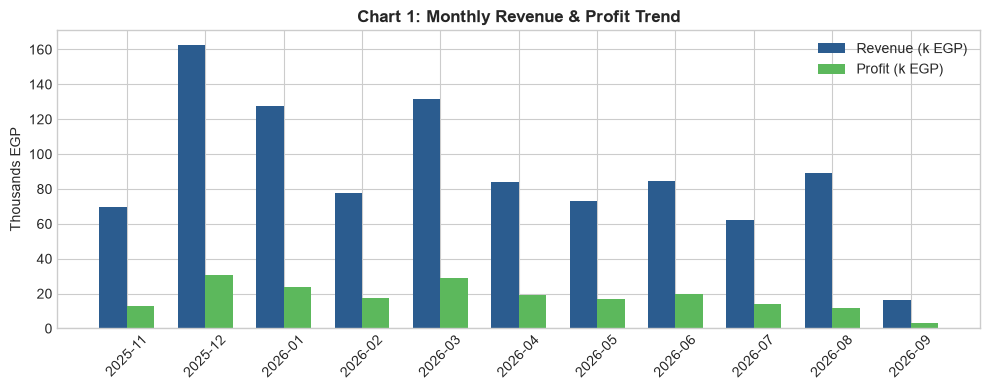

In [30]:
fig1, ax1 = plt.subplots(figsize=(10, 4))  #--> subplots() --> بينشئ الشكل ومحاور الرسم بمقاس محدد
width = 0.35  #--> بيحدد عرض كل عمود بياني
x = np.arange(len(monthly_trend))  #--> arange() --> بيولد مصفوفة أرقام متسلسلة لمواقع الأعمدة , len() --> بيحسب عدد الشهور
ax1.bar(x - width/2, monthly_trend['revenue']/1e3, width, label='Revenue (k EGP)', color='#2b5c8f')  #--> bar() --> بيرسم أعمدة الإيرادات بالآلاف
ax1.bar(x + width/2, monthly_trend['profit']/1e3, width, label='Profit (k EGP)', color='#5cb85c')  #--> bar() --> بيرسم أعمدة الأرباح بالآلاف
ax1.set_title('Chart 1: Monthly Revenue & Profit Trend', fontsize=12, fontweight='bold')  #--> set_title() --> بيحدد عنوان الرسم وحجم ووزن الخط
ax1.set_xticks(x)  #--> set_xticks() --> بيحدد أماكن علامات المحور الأفقي
ax1.set_xticklabels(monthly_trend['year_month'], rotation=45)  #--> set_xticklabels() --> بيحدد نصوص المحور الأفقي مع تدويرها 45 درجة
ax1.set_ylabel('Thousands EGP')  #--> set_ylabel() --> بيحدد تسمية المحور الرأسي
ax1.legend()  #--> legend() --> بيظهر صندوق مفاتيح الرسم البياني
plt.tight_layout()  #--> tight_layout() --> بيضبط هوامش ومسافات الرسم البياني تلقائياً
plt.show()  #--> show() --> بيعرض الرسم البياني على الشاشة

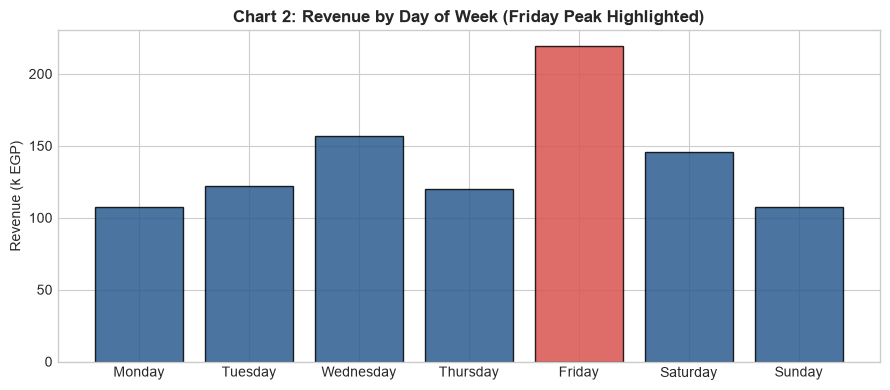

In [31]:
fig2, ax2 = plt.subplots(figsize=(9, 4))  #--> subplots() --> بينشئ الشكل والمحاور للرسم البياني
colors = ['#2b5c8f' if day != 'Friday' else '#d9534f' for day in weekday_summary['order_day_name']]  #--> قائمة ألوان لتمييز يوم الجمعة بلون مختلف عن باقي الأيام
ax2.bar(weekday_summary['order_day_name'], weekday_summary['revenue']/1e3, color=colors, edgecolor='black', alpha=0.85)  #--> bar() --> بيرسم أعمدة إيرادات أيام الأسبوع بالآلاف
ax2.set_title('Chart 2: Revenue by Day of Week (Friday Peak Highlighted)', fontsize=12, fontweight='bold')  #--> set_title() --> بيحدد عنوان الرسم البياني
ax2.set_ylabel('Revenue (k EGP)')  #--> set_ylabel() --> بيحدد تسمية المحور الرأسي
plt.tight_layout()  #--> tight_layout() --> بيضبط هوامش الرسم البياني تلقائياً
plt.show()  #--> show() --> بيعرض الرسم البياني على الشاشة

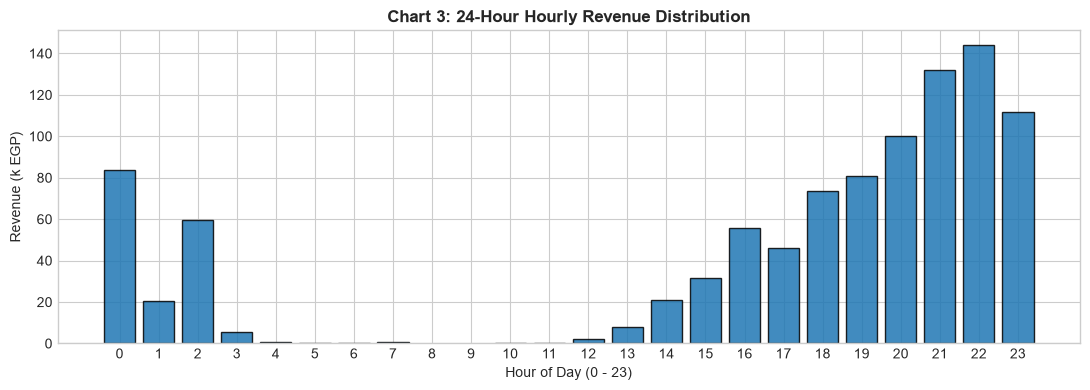

In [32]:
fig3, ax3 = plt.subplots(figsize=(11, 4))  #--> subplots() --> بينشئ مساحة ومحاور الرسم البياني
ax3.bar(hourly_summary['order_hour'], hourly_summary['revenue']/1e3, color='#1f77b4', edgecolor='black', alpha=0.85)  #--> bar() --> بيرسم أعمدة إيرادات ساعات اليوم على مدار 24 ساعة
ax3.set_title('Chart 3: 24-Hour Hourly Revenue Distribution', fontsize=12, fontweight='bold')  #--> set_title() --> بيحدد عنوان الرسم البياني
ax3.set_xlabel('Hour of Day (0 - 23)')  #--> set_xlabel() --> بيحدد تسمية المحور الأفقي لساعات اليوم
ax3.set_ylabel('Revenue (k EGP)')  #--> set_ylabel() --> بيحدد تسمية المحور الرأسي للإيراد بالآلاف
ax3.set_xticks(range(0, 24))  #--> set_xticks() --> range() --> بيحدد تدريج المحور الأفقي لكل ساعة من 0 إلى 23
plt.tight_layout()  #--> tight_layout() --> بيضبط هوامش ومسافات المخطط تلقائياً
plt.show()  #--> show() --> بيعرض الرسم البياني على الشاشة

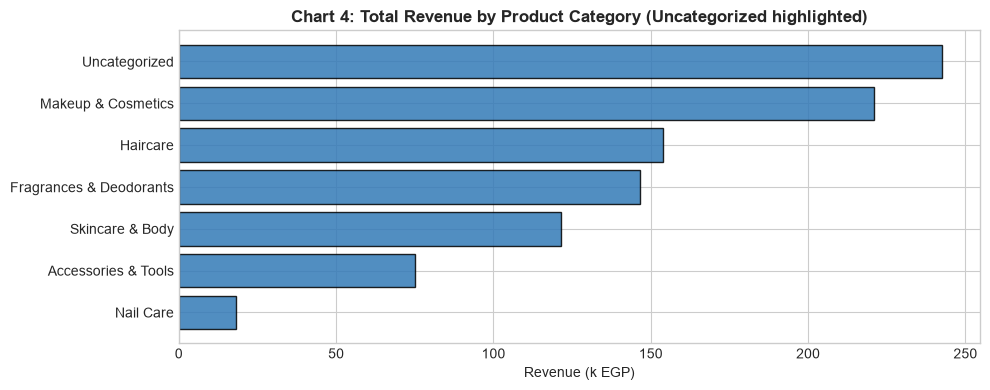

In [33]:
fig4, ax4 = plt.subplots(figsize=(10, 4))  #--> subplots() --> بينشئ الشكل والمحاور لرسم الأقسام
ax4.barh(dept_perf['product_category'], dept_perf['revenue']/1e3, color='#337ab7', edgecolor='black', alpha=0.85)  #--> barh() --> بيرسم مخطط أعمدة أفقي لإيرادات أقسام المنتجات بالآلاف
ax4.set_title('Chart 4: Total Revenue by Product Category (Uncategorized highlighted)', fontsize=12, fontweight='bold')  #--> set_title() --> بيحدد عنوان الرسم البياني
ax4.set_xlabel('Revenue (k EGP)')  #--> set_xlabel() --> بيحدد تسمية المحور الأفقي
ax4.invert_yaxis()  #--> invert_yaxis() --> بيعكس اتجاه المحور الرأسي ليبدأ بالقسم الأعلى إيراداً
plt.tight_layout()  #--> tight_layout() --> بيضبط هوامش المخطط تلقائياً
plt.show()  #--> show() --> بيعرض الرسم البياني على الشاشة

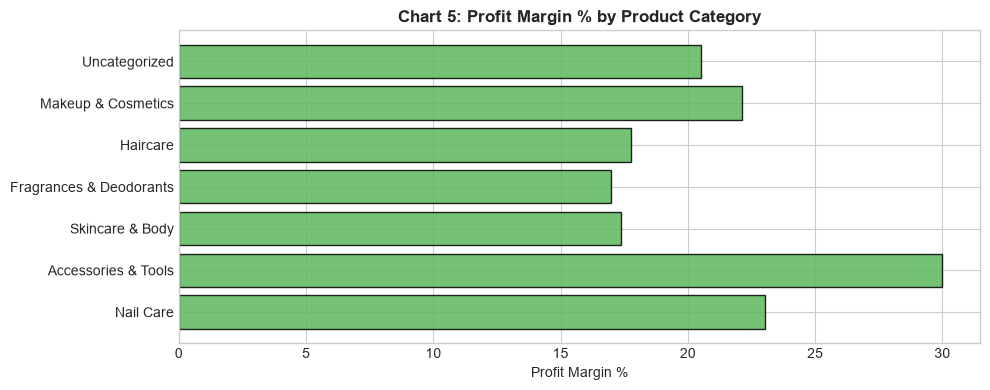

In [34]:
fig5, ax5 = plt.subplots(figsize=(10, 4))  #--> subplots() --> بينشئ مساحة ومحاور رسم هامش الربح
ax5.barh(dept_perf['product_category'], dept_perf['margin_pct'], color='#5cb85c', edgecolor='black', alpha=0.85)  #--> barh() --> بيرسم أعمدة أفقية لنسب هامش الربح لكل قسم
ax5.set_title('Chart 5: Profit Margin % by Product Category', fontsize=12, fontweight='bold')  #--> set_title() --> بيحدد عنوان المخطط البياني
ax5.set_xlabel('Profit Margin %')  #--> set_xlabel() --> بيحدد تسمية المحور الأفقي لنسبة الهامش
ax5.invert_yaxis()  #--> invert_yaxis() --> بيعكس المحور الرأسي لترتيب الأقسام من الأعلى للأسفل
plt.tight_layout()  #--> tight_layout() --> بيضبط هوامش الرسم البياني تلقائياً
plt.show()  #--> show() --> بيعرض الرسم البياني على الشاشة

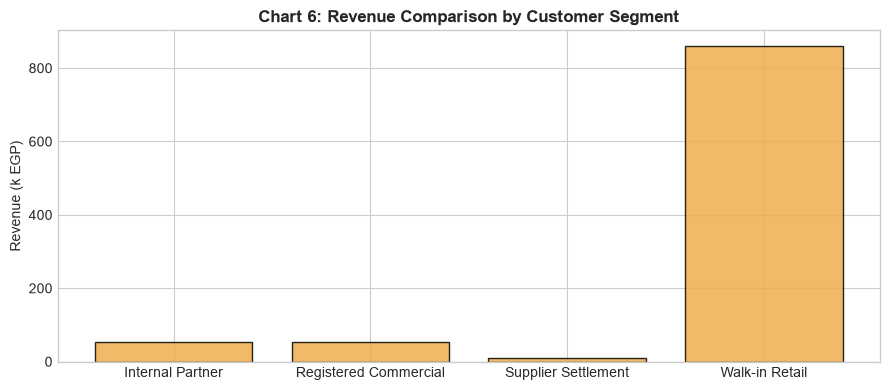

In [35]:
fig6, ax6 = plt.subplots(figsize=(9, 4))  #--> subplots() --> بينشئ الشكل والمحاور لمخطط شرائح العملاء
ax6.bar(segment_summary['customer_type'], segment_summary['revenue']/1e3, color='#f0ad4e', edgecolor='black', alpha=0.85)  #--> bar() --> بيرسم أعمدة رأسية لإيرادات كل شريحة عملاء بالآلاف
ax6.set_title('Chart 6: Revenue Comparison by Customer Segment', fontsize=12, fontweight='bold')  #--> set_title() --> بيحدد عنوان المخطط البياني
ax6.set_ylabel('Revenue (k EGP)')  #--> set_ylabel() --> بيحدد تسمية المحور الرأسي للإيرادات بالآلاف
plt.tight_layout()  #--> tight_layout() --> بيضبط الهوامش تلقائياً
plt.show()  #--> show() --> بيعرض الرسم البياني على الشاشة

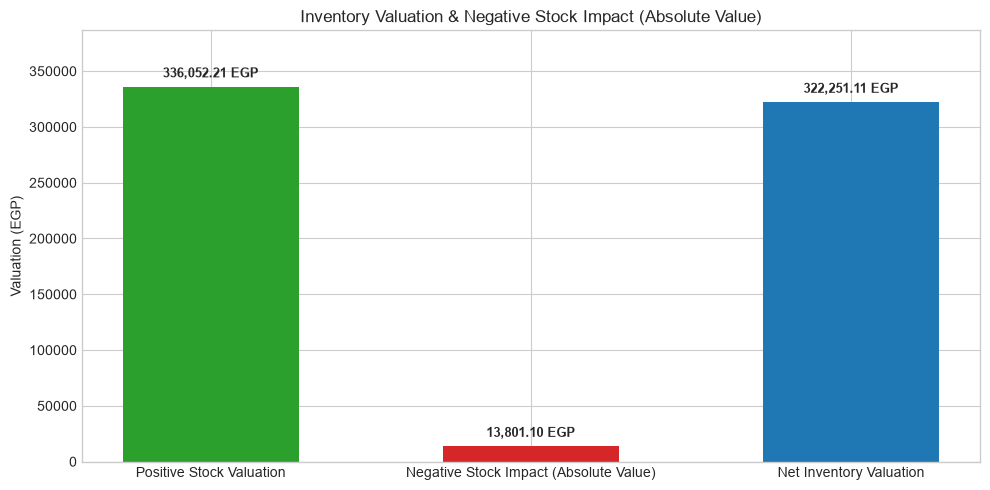

In [36]:
plt.figure(figsize=(10, 5))  #--> figure() --> بينشئ شكلاً بيانياً جديداً بالأبعاد المحددة
inv_components = [  #--> قائمة بمكونات تقييم المخزون المالي
    'Positive Stock Valuation',  #--> تقييم المخزون الموجب
    'Negative Stock Impact (Absolute Value)',  #--> أثر المخزون السالب بالقيمة المطلقة
    'Net Inventory Valuation'  #--> صافي تقييم المخزون الكلي
]  #--> نهاية القائمة
inv_values = [  #--> قائمة بالقيم المالية المقابلة لكل مكون
    positive_valuation_val,  #--> قيمة المخزون الموجب
    abs(negative_valuation_val),  #--> abs() --> القيمة المطلقة للأثر السالب
    net_valuation  #--> صافي قيمة المخزون الكلية
]  #--> نهاية قائمة القيم
colors = ['#2ca02c', '#d62728', '#1f77b4']  #--> قائمة الألوان المخصصة للأعمدة البيانية

bars = plt.bar(inv_components, inv_values, color=colors, width=0.55)  #--> bar() --> بيرسم الأعمدة البيانية للمخزون
for bar in bars:  #--> حلقة تكرارية لكتابة القيمة المالية أعلى كل عمود
    height = bar.get_height()  #--> get_height() --> بيستخرج ارتفاع وقيمة العمود الحالي
    plt.text(bar.get_x() + bar.get_width()/2., height + 6000,  #--> text() --> get_x() --> get_width() --> بيضع النص في منتصف العمود وأعلى قمته
             f"{height:,.2f} EGP", ha='center', va='bottom', fontsize=9, fontweight='bold')  #--> تنسيق النص وتحديد محاذاته وحجم الخط

plt.title('Inventory Valuation & Negative Stock Impact (Absolute Value)')  #--> title() --> بيحدد عنوان المخطط البياني
plt.ylabel('Valuation (EGP)')  #--> ylabel() --> بيحدد تسمية المحور الرأسي بالجنيه المصري
plt.ylim(0, max(inv_values) * 1.15)  #--> ylim() --> max() --> بيحدد نطاق المحور الرأسي ليتسع للنصوص أعلى الأعمدة
plt.tight_layout()  #--> tight_layout() --> بيضبط الهوامش تلقائياً
plt.show()  #--> show() --> بيعرض الرسم البياني على الشاشة

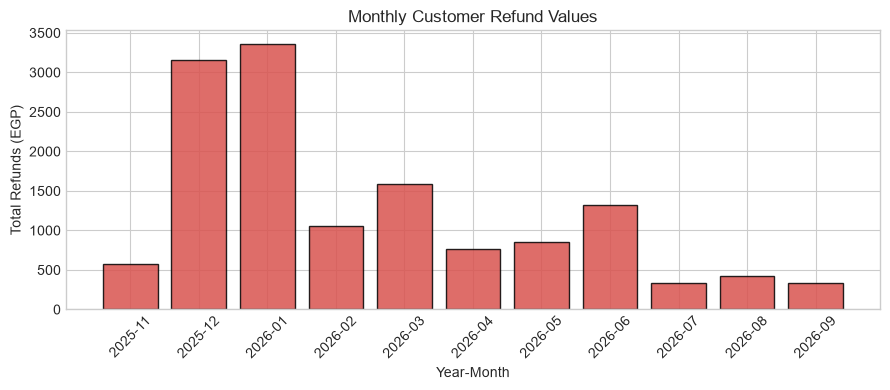

In [37]:
returns_invoices_df['year_month'] = returns_invoices_df['return_date'].str[:7]  #--> str[:7] --> بيستخرج السنة والشهر من تاريخ المرتجع
monthly_returns_trend = returns_invoices_df.groupby('year_month')['final_total'].sum().abs().reset_index()  #--> groupby() --> بيجمع فواتير المرتجعات شهرياً , sum() --> بيجمع قيم المرتجعات , abs() --> بيرجع القيمة الموجبة المطلقة , reset_index() --> بيحول الناتج لجدول

plt.figure(figsize=(9, 4))  #--> figure() --> بينشئ شكلاً بيانياً جديداً بالأبعاد المحددة
plt.bar(monthly_returns_trend['year_month'], monthly_returns_trend['final_total'], color='#d9534f', edgecolor='black', alpha=0.85)  #--> bar() --> بيرسم أعمدة المرتجعات الشهرية
plt.title('Monthly Customer Refund Values')  #--> title() --> بيحدد عنوان الرسم البياني
plt.xlabel('Year-Month')  #--> xlabel() --> بيحدد تسمية المحور الأفقي بالشهور
plt.ylabel('Total Refunds (EGP)')  #--> ylabel() --> بيحدد تسمية المحور الرأسي لإجمالي المبالغ المستردة
plt.xticks(rotation=45)  #--> xticks(rotation=45) --> بيقوم بتدوير نصوص الشهور على المحور الأفقي بمقدار 45 درجة
plt.tight_layout()  #--> tight_layout() --> بيضبط هوامش الرسم البياني تلقائياً
plt.show()  #--> show() --> بيعرض الرسم البياني على الشاشة

##  Financial Reconciliation & Tie-Out
Each line amount is rounded to 2 decimals, so the sum of many rounded lines can differ by a few hundredths from the rounded invoice total

In [38]:
total_profit = sales_invoices_df['profit'].sum()  #--> sum() --> بيحسب المجموع الكلي لأرباح المبيعات

sales_items_line_sum = sales_items_df['line_final'].sum()  #--> sum() --> بيحسب مجموع سطور بنود المبيعات
purchase_items_line_sum = purchase_items_df['line_final'].sum()  #--> sum() --> بيحسب مجموع سطور بنود المشتريات
returns_items_line_sum = returns_items_df['line_final'].sum()  #--> sum() --> بيحسب مجموع سطور بنود المرتجعات

recon_specs = [  #--> قائمة تضم مواصفات المطابقة المالية والتشغيلية لكل مقياس
    ("Gross Sales Revenue (EGP)", total_revenue, 978248.29, 0.01, False),  #--> مطابقة إجمالي الإيرادات
    ("Sales Items Lines Total (EGP)", sales_items_line_sum, 978248.29, 0.02, False),  #--> مطابقة مجموع بنود المبيعات
    ("Gross Profit (EGP)", total_profit, 198590.41, 0.01, False),  #--> مطابقة مجمل الأرباح
    ("Sales Invoices Count", total_invoices, 5505, 0.00, True),  #--> مطابقة عدد فواتير المبيعات
    ("Sales Line Items Count", len(sales_items_df), 10891, 0.00, True),  #--> len() --> مطابقة عدد بنود فواتير المبيعات
    ("Purchase Invoices Count", len(purchase_invoices_df), 32, 0.00, True),  #--> len() --> مطابقة عدد فواتير المشتريات
    ("Purchase Line Items Count", len(purchase_items_df), 1658, 0.00, True),  #--> len() --> مطابقة عدد بنود فواتير المشتريات
    ("Total Purchases Value (EGP)", purchase_invoices_df['final_total'].sum(), 1118614.71, 0.01, False),  #--> sum() --> مطابقة إجمالي قيمة المشتريات
    ("Purchase Items Lines Total (EGP)", purchase_items_line_sum, 1118614.71, 0.02, False),  #--> sum() --> مطابقة مجموع بنود المشتريات
    ("Sales Return Invoices Count", len(returns_invoices_df), 127, 0.00, True),  #--> len() --> مطابقة عدد فواتير المرتجعات
    ("Sales Return Items Count", len(returns_items_df), 157, 0.00, True),  #--> len() --> مطابقة عدد بنود المرتجعات
    ("Total Returns Value (EGP)", returns_invoices_df['final_total'].sum(), -13779.78, 0.01, False),  #--> sum() --> مطابقة إجمالي قيمة المرتجعات
    ("Return Items Lines Total (EGP)", returns_items_line_sum, -13779.78, 0.02, False),  #--> sum() --> مطابقة مجموع بنود المرتجعات
    ("Returns Profit Impact (EGP)", returns_items_df['profit'].sum(), -3020.12, 0.01, False),  #--> sum() --> مطابقة أثر المرتجعات على الأرباح
    ("Total Catalog SKUs", len(products_df), 1437, 0.00, True),  #--> len() --> مطابقة إجمالي عدد الأصناف في الكتالوج
    ("Total Accounts Count", len(accounts_df), 37, 0.00, True),  #--> len() --> مطابقة إجمالي عدد الحسابات
    ("Positive Stock Valuation (EGP)", positive_valuation_val, 336052.21, 0.01, False),  #--> مطابقة تقييم المخزون الموجب
    ("Negative Stock Impact (EGP)", negative_valuation_val, -13801.10, 0.01, False),  #--> مطابقة أثر المخزون السالب
    ("Net Inventory Valuation (EGP)", net_valuation, 322251.11, 0.01, False),  #--> مطابقة صافي تقييم المخزون
    ("Negative-Quantity SKUs Count", negative_qty_skus, 84, 0.00, True),  #--> مطابقة عدد الأصناف ذات الرصيد السالب
    ("Non-Negative Quantity SKUs (total_qty >= 0)", non_negative_qty_skus, 1353, 0.00, True),  #--> مطابقة عدد الأصناف ذات الرصيد غير السالب
    ("Positive-Cost Negative SKUs Count", negative_cost_skus, 81, 0.00, True),  #--> مطابقة الأصناف السالبة ذات التكلفة الموجبة
    ("Zero-Cost Negative SKUs Count", len(zero_cost_neg), 3, 0.00, True),  #--> len() --> مطابقة الأصناف السالبة ذات التكلفة الصفرية
] 

recon_rows = []  #--> قائمة لتجميع صفوف نتائج التدقيق والمطابقة
for name, comp, bench, tol, is_cnt in recon_specs:  #--> حلقة تكرارية لفحص ومطابقة كل مقياس محسوب مع المعيار
    diff = comp - bench  #--> بيحسب الفرق الحسابي بين القيمة المحسوبة وقيمة المعيار
    status = "PASS" if abs(diff) <= tol + 1e-9 else "FAIL"  #--> abs() --> بيحدد حالة النجاح في حال كان الفرق ضمن حدود التفاوت المسموح بها
    comp_str = f"{int(comp):,d}" if is_cnt else f"{comp:,.2f}"  #--> int() --> بينسق القيمة المحسوبة إما كعدد صحيح أو رقم عشري
    bench_str = f"{int(bench):,d}" if is_cnt else f"{bench:,.2f}"  #--> int() --> بينسق قيمة المعيار المرجعي
    diff_str = f"{int(diff):,d}" if is_cnt else f"{diff:.4f}"  #--> int() --> بينسق فرق الحساب للتأكد من التطابق
    recon_rows.append({  #--> append() --> بيضيف نتيجة فحص المقياس إلى قائمة النتائج
        "Metric": name,  #--> اسم المقياس
        "Computed": comp_str,  #--> القيمة المحسوبة
        "Benchmark": bench_str,  #--> القيمة المعيارية المعتمدة
        "Tolerance": f"{tol:.2f}",  #--> حد التفاوت المسموح
        "Difference": diff_str  #--> الفرق الفعلي
    })

recon_df = pd.DataFrame(recon_rows)  #--> DataFrame() --> بينشئ جدول المطابقة الشامل للتحقق من الأرقام
display(recon_df)  #--> display() --> بيعرض جدول نتائج المطابقة المالية والتشغيلية

print(f"\nInformational Note: Positive-valuation SKUs count is {positive_valuation_skus} (valuation > 0)")  #--> print() --> بيطبع ملاحظة توضيحية لعدد الأصناف ذات التقييم الإيجابي

,Metric,Computed,Benchmark,Tolerance,Difference
0,Gross Sales Revenue (EGP),"978,248.29","978,248.29",0.01,0.0000
1,Sales Items Lines Total (EGP),"978,248.28","978,248.29",0.02,-0.0099
2,Gross Profit (EGP),"198,590.41","198,590.41",0.01,-0.0039
3,Sales Invoices Count,"5,505","5,505",0.00,0
4,Sales Line Items Count,"10,891","10,891",0.00,0
5,Purchase Invoices Count,32,32,0.00,0
6,Purchase Line Items Count,"1,658","1,658",0.00,0
7,Total Purchases Value (EGP),"1,118,614.71","1,118,614.71",0.01,0.0000
8,Purchase Items Lines Total (EGP),"1,118,614.70","1,118,614.71",0.02,-0.0069
9,Sales Return Invoices Count,127,127,0.00,0



Informational Note: Positive-valuation SKUs count is 896 (valuation > 0)


##  Academic Defense Summary
This section summarizes what we found. First we list the facts. All numbers are printed from the data. Then we write what the facts may mean, and what the limits of the analysis are.

In [39]:
overall_margin = total_profit / total_revenue * 100  #--> بيحسب النسبة المئوية لهامش الربح الإجمالي
avg_order = total_revenue / total_invoices  #--> بيحسب متوسط قيمة الفاتورة الكلي

walkin_count = len(walkin_invoices)  #--> len() --> بيحسب عدد فواتير عملاء القطاعي
walkin_rev = walkin_invoices['final_total'].sum()  #--> sum() --> بيجمع إجمالي إيرادات عملاء القطاعي
walkin_orders_share = walkin_count / total_invoices * 100  #--> بيحسب حصة فواتير القطاعي من إجمالي عدد الفواتير
walkin_rev_share = walkin_rev / total_revenue * 100  #--> بيحسب حصة إيرادات القطاعي من إجمالي الإيرادات

comm_count = len(commercial_invoices)  #--> len() --> بيحسب عدد فواتير العملاء التجاريين
comm_rev = commercial_invoices['final_total'].sum()  #--> sum() --> بيجمع إجمالي إيرادات العملاء التجاريين
comm_profit = commercial_invoices['profit'].sum()  #--> sum() --> بيجمع إجمالي أرباح العملاء التجاريين
comm_aov = comm_rev / comm_count  #--> بيحسب متوسط قيمة الفاتورة للعملاء التجاريين
comm_margin = comm_profit / comm_rev * 100  #--> بيحسب هامش الربح المئوي للعملاء التجاريين

partner_count = len(partner_txns)  #--> len() --> بيحسب عدد فواتير معاملات الشريك
partner_rev = partner_txns['final_total'].sum()  #--> sum() --> بيجمع إجمالي إيرادات معاملات الشريك

ext_count = len(external_demand)  #--> len() --> بيحسب عدد فواتير العملاء الخارجيين
ext_rev = external_demand['final_total'].sum()  #--> sum() --> بيجمع إجمالي إيرادات العملاء الخارجيين

friday = weekday_summary[weekday_summary['order_day_name'] == 'Friday']  #--> بيصفي صف بيانات يوم الجمعة من جدول الأسبوع
friday_orders = friday['orders'].values[0]  #--> بيستخرج عدد طلبات يوم الجمعة
friday_rev = friday['revenue'].values[0]  #--> بيستخرج إيرادات يوم الجمعة
friday_share = friday_rev / total_revenue * 100  #--> بيحسب نسبة إيرادات يوم الجمعة من المبيعات الكلية

latenight_share = combined_latenight_rev / total_revenue * 100  #--> بيحسب نسبة مبيعات الفترة المسائية المتأخرة من المبيعات الكلية

net_val = products_df['stock_cost_valuation'].sum()  #--> sum() --> بيحسب صافي تقييم المخزون
sku_count = len(products_df)  #--> len() --> بيحسب إجمالي عدد أصناف الكتالوج
neg_sku_count = len(products_df[products_df['total_qty'] < 0])  #--> len() --> بيحسب عدد الأصناف ذات الرصيد السالب

return_count = len(returns_invoices_df)  #--> len() --> بيحسب عدد فواتير المرتجعات
total_returns_val = returns_invoices_df['final_total'].sum()  #--> sum() --> بيجمع إجمالي قيمة المرتجعات
refund_rate = abs(total_returns_val) / total_revenue * 100  #--> abs() --> بيرجع القيمة المطلقة لحساب معدل الاسترداد النقدي

last_sale = pd.to_datetime(sales_invoices_df['invoice_date'].max())  #--> to_datetime() --> max() --> بيحول أحدث تاريخ بيع لنوع تاريخ ووقت
last_return = pd.to_datetime(returns_invoices_df['return_date'].max())  #--> to_datetime() --> max() --> بيحول أحدث تاريخ مرتجع لنوع تاريخ ووقت
days_between = (last_return - last_sale).days  #--> days --> بيحسب فرق الأيام بين آخر مرتجع وآخر عملية بيع

print("Overall") 
print(f"Revenue: {total_revenue:,.2f} EGP, profit: {total_profit:,.2f} EGP, margin: {overall_margin:.2f}%")  #--> print() --> بيطبع الإيراد والربح ونسبة الهامش
print(f"Invoices: {total_invoices:,}, average order: {avg_order:,.2f} EGP")  #--> print() --> بيطبع إجمالي الفواتير ومتوسط الفاتورة
print()  

print("Customer segments")  #--> print() --> بيطبع عنوان شرائح العملاء
print(f"Walk-in Retail: {walkin_count:,} invoices ({walkin_orders_share:.2f}%), {walkin_rev:,.2f} EGP ({walkin_rev_share:.2f}% of revenue)")  #--> print() --> بيطبع أرقام شريحة القطاعي
print(f"Registered Commercial: {comm_count} invoices, {comm_rev:,.2f} EGP, average order {comm_aov:,.2f} EGP, margin {comm_margin:.2f}%")  #--> print() --> بيطبع أرقام الشريحة التجارية
print(f"Internal Partner Transactions: {partner_count} invoices, {partner_rev:,.2f} EGP")  #--> print() --> بيطبع أرقام شريحة الشريك الداخلي
print(f"Invoice #5328: {inv_5328['final_total']:,.2f} EGP, which is {share_of_partner:.2f}% of Internal Partner revenue")  #--> print() --> بيطبع تفاصيل الفاتورة رقم 5328
print(f"External Customer Transactions (Walk-in + Registered Commercial): {ext_count:,} invoices, {ext_rev:,.2f} EGP")  #--> print() --> بيطبع أرقام المعاملات الخارجية المجمعة
print() 

print("August 2026")  #--> print() --> بيطبع عنوان مقارنة شهر أغسطس
print(f"With invoice #5328: {rev_all:,.2f} EGP, margin {margin_all:.2f}%")  #--> print() --> بيطبع إيراد وهامش أغسطس شامل الفاتورة
print(f"Without invoice #5328: {rev_excl:,.2f} EGP, margin {margin_excl:.2f}%")  #--> print() --> بيطبع إيراد وهامش أغسطس بدون الفاتورة
print()  

print("Operating times") 
print(f"Friday: {friday_rev:,.2f} EGP from {friday_orders:,} orders ({friday_share:.2f}% of total recorded revenue)")  #--> print() --> بيطبع إيرادات وأوامر يوم الجمعة
print(f"From 20:00 to 03:59: {combined_latenight_rev:,.2f} EGP ({latenight_share:.2f}% of recorded revenue)")  #--> print() --> بيطبع إيرادات وحصة الفترة الليلية
print() 

print("Inventory and returns")  #--> print() --> بيطبع عنوان المخزون والمرتجهات
print(f"Net inventory valuation: {net_val:,.2f} EGP for {sku_count:,} products")  #--> print() --> بيطبع صافي تقييم المخزون وعدد الأصناف
print(f"Products with negative quantity: {neg_sku_count}")  #--> print() --> بيطبع عدد المنتجات ذات الكمية السالبة
print(f"Returns: {return_count} invoices, {total_returns_val:,.2f} EGP, monetary refund rate {refund_rate:.2f}%")  #--> print() --> بيطبع إحصاءات المرتجعات ونسبة الاسترداد
print(f"The last return is {days_between} days after the last sales invoice")  #--> print() --> بيطبع الفرق الزمني لآخر مرتجع

Overall
Revenue: 978,248.29 EGP, profit: 198,590.41 EGP, margin: 20.30%
Invoices: 5,505, average order: 177.70 EGP

Customer segments
Walk-in Retail: 5,417 invoices (98.40%), 859,532.14 EGP (87.86% of revenue)
Registered Commercial: 57 invoices, 53,161.65 EGP, average order 932.66 EGP, margin 24.81%
Internal Partner Transactions: 26 invoices, 54,684.50 EGP
Invoice #5328: 47,207.00 EGP, which is 86.33% of Internal Partner revenue
External Customer Transactions (Walk-in + Registered Commercial): 5,474 invoices, 912,693.79 EGP

August 2026
With invoice #5328: 89,226.14 EGP, margin 13.32%
Without invoice #5328: 42,019.14 EGP, margin 22.12%

Operating times
Friday: 219,197.20 EGP from 963 orders (22.41% of total recorded revenue)
From 20:00 to 03:59: 657,337.39 EGP (67.20% of recorded revenue)

Inventory and returns
Net inventory valuation: 322,251.11 EGP for 1,437 products
Products with negative quantity: 84
Returns: 127 invoices, -13,779.78 EGP, monetary refund rate 1.41%
The last return 

### Limitations
These are the limits of this analysis. The numbers below are printed from the data.

In [40]:
first_sale_date = str(sales_invoices_df['invoice_date'].min())[:10]  #--> min() --> بيحدد أقدم تاريخ بيع , str()[:10] --> بيستخرج أول 10 أحرف للتاريخ
last_sale_date = str(sales_invoices_df['invoice_date'].max())[:10]  #--> max() --> بيحدد أحدث تاريخ بيع , str()[:10] --> بيستخرج أول 10 أحرف للتاريخ
nov_days = monthly_trend.loc[monthly_trend['year_month'] == '2025-11', 'unique_sale_days'].values[0]  #--> loc[] --> بيستخرج عدد أيام العمل الفعلية لشهر نوفمبر 2025
sep_days = monthly_trend.loc[monthly_trend['year_month'] == '2026-09', 'unique_sale_days'].values[0]  #--> loc[] --> بيستخرج عدد أيام العمل الفعلية لشهر سبتمبر 2026
zero_cost_count = len(zero_cost_neg)  #--> len() --> بيحسب عدد الأصناف ذات الرصيد السالب والتكلفة الصفرية
uncat_total = len(products_df[products_df['product_category'] == 'Uncategorized'])  #--> len() --> بيحسب إجمالي المنتجات غير المصنفة
uncat_beauty = len(products_df[(products_df['product_scope'] == 'In-Scope (Beauty)') & (products_df['product_category'] == 'Uncategorized')])  #--> len() --> بيحسب منتجات التجميل داخل النطاق وغير المصنفة

print(f"1. The data covers one store from {first_sale_date} to {last_sale_date}. We cannot say if the same patterns repeat in other periods")  #--> print() --> بيطبع قيد التغطية الزمنية للمتجر
print(f"2. November 2025 has {nov_days} sale days and September 2026 has {sep_days}, so these two months are partial")  #--> print() --> بيطبع قيد الأشهر غير الكاملة
print(f"3. {zero_cost_count} products have a negative quantity and zero purchase cost, so they cannot be valued")  #--> print() --> بيطبع قيد الأصناف السالبة بدون تكلفة
print(f"4. {uncat_total} products have no department, and {uncat_beauty} of them are In-Scope Beauty. They make {uncat_share_pct:.2f}% of line revenue")  #--> print() --> بيطبع قيد الأصناف غير المصنفة ومساهمتها المالية
print("5. Profit depends on the cost values recorded in the data")  #--> print() --> بيطبع قيد اعتماد الربحية على التكاليف المسجلة
print("6. The data has no information about why sales or returns happen, so this notebook describes what happened and does not explain causes")  #--> print() --> بيطبع قيد طبيعة التحليل الوصفي

1. The data covers one store from 2025-11-28 to 2026-09-14. We cannot say if the same patterns repeat in other periods
2. November 2025 has 3 sale days and September 2026 has 14, so these two months are partial
3. 3 products have a negative quantity and zero purchase cost, so they cannot be valued
4. 384 products have no department, and 132 of them are In-Scope Beauty. They make 24.79% of line revenue
5. Profit depends on the cost values recorded in the data
6. The data has no information about why sales or returns happen, so this notebook describes what happened and does not explain causes
